## Table of Contents

1. [Imports](#Imports)
2. [Dataset Column Description](#Dataset-Column-Description)
3. [Data Loading](#Data-Loading)
4. [Table Overview](#Table-Overview)
5. [Target Distribution](#Target-Distribution)
6. [Missing Values](#Missing-Values)
7. [Numerical Features and Anomalies](#Numerical-Features-and-Anomalies)
8. [Categorical Features and Target](#Categorical-Features-and-Target)
9. [Feature Correlations](#Feature-Correlations)
10. [Temporal and Demand Dynamics](#Temporal-and-Demand-Dynamics)
11. [Preprocessing Plan](#Preprocessing-Plan)
12. [EDA Conclusion](#EDA-Conclusion)


In [40]:
%reload_ext autoreload
%autoreload 2

# Imports
[Table of Contents](#Table-of-Contents)

In [41]:
import os
import sys

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import phik

## Dataset Column Description
[Table of Contents](#Table-of-Contents)

| Столбец | Тип | Описание |
|---|---|---|
| **Date** | str (date) | Дата наблюдения в формате `DD/MM/YYYY` |
| **Rented Bike Count** | int | Количество арендованных велосипедов за час — **целевая переменная** |
| **Hour** | int | Час суток (0–23) |
| **Temperature(°C)** | float | Температура воздуха в градусах Цельсия |
| **Humidity(%)** | int | Влажность воздуха, % |
| **Wind speed (m/s)** | float | Скорость ветра, м/с |
| **Visibility (10m)** | int | Видимость в единицах по 10 м (т.е. 2000 = 20 км) |
| **Dew point temperature(°C)** | float | Точка росы, °C |
| **Solar Radiation (MJ/m²)** | float | Солнечная радиация, МДж/м² |
| **Rainfall(mm)** | float | Количество осадков в виде дождя, мм |
| **Snowfall (cm)** | float | Количество осадков в виде снега, см |
| **Seasons** | str | Время года: `Winter`, `Spring`, `Summer`, `Autumn` |
| **Holiday** | str | `Holiday` / `No holiday` — праздничный день или нет |
| **Functioning Day** | str | `Yes` / `No` — работал ли прокат в этот час (`NoFunc` = нерабочие часы) |

## Data Loading
[Table of Contents](#Table-of-Contents)

In [42]:
path = kagglehub.dataset_download("joebeachcapital/seoul-bike-sharing")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\mapke\.cache\kagglehub\datasets\joebeachcapital\seoul-bike-sharing\versions\1


In [43]:
file_path = os.path.join(path, "SeoulBikeData.csv")
df = pd.read_csv(file_path, encoding="unicode_escape")

## Table Overview
[Table of Contents](#Table-of-Contents)

In [44]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [46]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [47]:
import re


def norm_col(c: str) -> str:
    c = str(c).strip().lower()
    c = c.replace('°c', '').replace('°', '')
    c = c.replace('%', '')
    c = c.replace('(', '').replace(')', '')
    c = c.replace('/', '_')
    c = re.sub(r'\s+', '_', c)
    c = re.sub(r'_+', '_', c).strip('_')
    return c

print("Before:", df.columns.tolist())
df.columns = [norm_col(c) for c in df.columns]
print("After norm:", df.columns.tolist())

final_map = {
    'wind_speed_m_s':             'wind_speed',
    'visibility_10m':             'visibility',
    'dew_point_temperature':      'dew_point_temp',
    'solar_radiation_mj_m2':      'solar_radiation',
    'rainfallmm':                 'rainfall',
    'snowfall_cm':                'snowfall',
}
df = df.rename(columns=final_map)
print("After rename:", df.columns.tolist())

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

cat_cols = ['seasons', 'holiday', 'functioning_day']
df[cat_cols] = df[cat_cols].astype('category')

print("\n" + "=" * 60)
df.info()

Before: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']
After norm: ['date', 'rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed_m_s', 'visibility_10m', 'dew_point_temperature', 'solar_radiation_mj_m2', 'rainfallmm', 'snowfall_cm', 'seasons', 'holiday', 'functioning_day']
After rename: ['date', 'rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temp', 'solar_radiation', 'rainfall', 'snowfall', 'seasons', 'holiday', 'functioning_day']

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               8760 non-null   datetime64[us]
 1   rented_bike_count  8760 non-null   int64 

### Вывод

В таблице 8 760 строк и 14 столбцов. По постановке одна строка
соответствует одному часу. `date` и `hour` задают дату и час наблюдения,
`rented_bike_count` — число аренд за этот час. Остальные столбцы описывают
погоду, сезон, праздничный статус и работу сервиса.

Названия столбцов приведены к единому формату. `date` преобразован
в тип даты, `hour` хранится как целое число, а `seasons`, `holiday`
и `functioning_day` — как категориальные признаки.

## Target Distribution
[Table of Contents](#Table-of-Contents)

In [48]:
sys.path.append(os.path.abspath(".."))
from src.dist_comparison import plot_distribution_pair
from src.get_distribution_stats import analyze_distribution

In [49]:
stats = analyze_distribution(
    df['rented_bike_count']
)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 704.6021 | Медиана: 504.5000 | Std: 644.9975
Min / Max: 0.0000 / 3556.0000
Q1: 191.0000 | Q3: 1065.2500 | IQR: 874.2500
IQR-пороги: [-1120.3750, 2376.6250]
За IQR-порогами: 158 (1.80%) | Ниже: 0 | Выше: 158
Нули: 295 (3.37%)
Асимметрия: 1.1534 | Эксцесс: 0.8534

Процентили:
0.000       0.000
0.001       0.000
0.010       0.000
0.050      22.000
0.250     191.000
0.500     504.500
0.750    1065.250
0.950    2043.000
0.990    2526.230
0.999    3261.061
1.000    3556.000
Name: rented_bike_count, dtype: float64


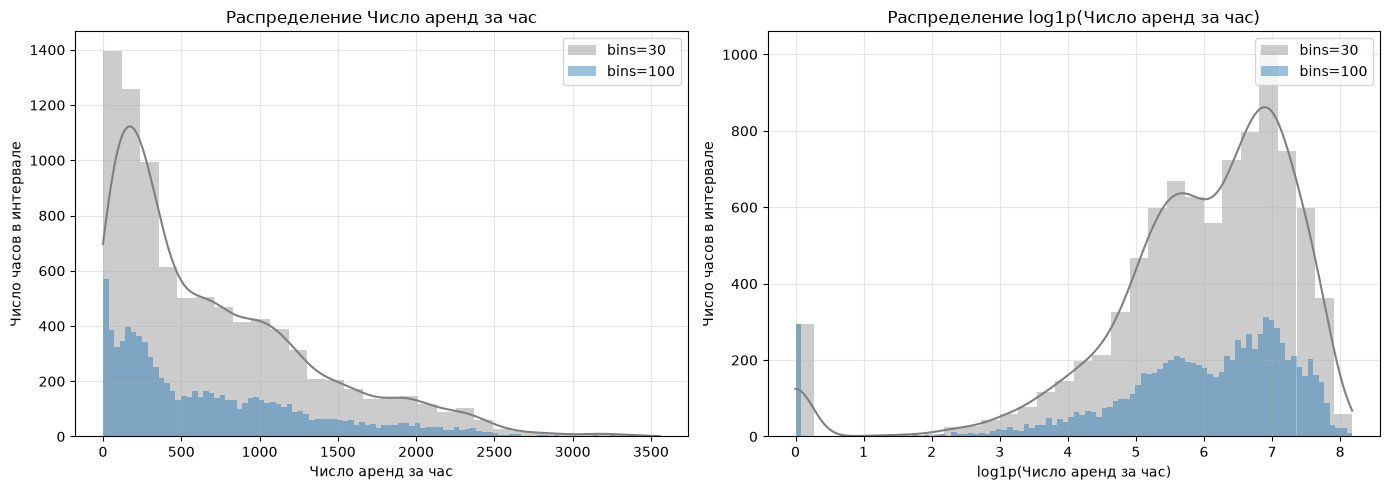

In [50]:
fig, axes = plot_distribution_pair(
    df['rented_bike_count'],
    feature_name="Число аренд за час",
    bins=(30, 100),
    kde=True,
    ylabel="Число часов в интервале",
    clip_quantiles=(0.00, 1.0),
)

In [51]:
target = df['rented_bike_count']

print("НУЛЕВЫЕ ЗНАЧЕНИЯ")
print("-" * 60)
zero_mask = target == 0
zero_cnt = zero_mask.sum()
print(f"Нулей всего:           {zero_cnt:,} ({zero_cnt / len(target) * 100:.2f}%)")

if 'functioning_day' in df.columns:
    zeros_non_func = df.loc[df['functioning_day'] == 'No', 'rented_bike_count'].eq(0).sum()
    zeros_func     = df.loc[df['functioning_day'] == 'Yes', 'rented_bike_count'].eq(0).sum()
    print(f"  из них Functioning Day = No:  {zeros_non_func:,}")
    print(f"  из них Functioning Day = Yes: {zeros_func:,}")

НУЛЕВЫЕ ЗНАЧЕНИЯ
------------------------------------------------------------
Нулей всего:           295 (3.37%)
  из них Functioning Day = No:  295
  из них Functioning Day = Yes: 0


Все нули объясняются нерабочими часами (не выбросы)

### Conclusion: Target Distribution

Распределение `rented_bike_count` асимметрично вправо: коэффициент асимметрии
составляет около 1,15, а среднее выше медианы. На полном наборе 295 часов
(3,37 %) имеют нулевое число аренд. Все эти часы относятся к
`functioning_day == "No"`; среди часов со статусом `Yes` нулевых аренд нет.

В baseline оставляем таргет в исходных единицах — количестве аренд.
Правую асимметрию рассматриваем как мотивацию для отдельного эксперимента,
а не как требование преобразовать таргет.

## Missing Values
[Table of Contents](#Table-of-Contents)

In [52]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

pd.DataFrame({'Пропуски (шт)': missing_values, 'Пропуски (%)': missing_percent})

,Пропуски (шт),Пропуски (%)
date,0,0.0
rented_bike_count,0,0.0
hour,0,0.0
temperature,0,0.0
humidity,0,0.0
wind_speed,0,0.0
visibility,0,0.0
dew_point_temp,0,0.0
solar_radiation,0,0.0
rainfall,0,0.0


In [53]:
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates}")

time_duplicates = df.duplicated(subset=['date', 'hour']).sum()
print(f"Дубликатов по связке (date + hour): {time_duplicates}")

Полных дубликатов: 0
Дубликатов по связке (date + hour): 0


In [54]:
display(df.describe().T)

display(df.describe(include=['category', 'object']).T)

,count,mean,min,25%,50%,75%,max,std
date,8760,2018-06-01 00:00:00,2017-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
rented_bike_count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
temperature,8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
humidity,8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
wind_speed,8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
visibility,8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
dew_point_temp,8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
solar_radiation,8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
rainfall,8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193


,count,unique,top,freq
seasons,8760,4,Spring,2208
holiday,8760,2,No Holiday,8328
functioning_day,8760,2,Yes,8465


### Conclusion: Missing Values

На полном наборе `isna()` не выявил пропусков ни в одном столбце.
Полных дубликатов строк и повторов пары `date` + `hour` также не обнаружено.
По результатам этой проверки импутация и удаление дубликатов для baseline
не требуются.

Отсутствие пропусков не означает, что все измерения корректны:
подозрительные значения рассматриваем отдельно в разделе
`Numerical Features and Anomalies`.

## Numerical Features and Anomalies
[Table of Contents](#Table-of-Contents)

### Numerical Features Index

- [Boxplot для всех численных признаков](#Boxplot-for-all-numerical-features)
- [Температура — обзор](#Temperature-Overview)
- [Влажность — обзор](#Humidity-Overview)
- [Скорость ветра — обзор](#Wind-Speed-Overview)
- [Видимость — обзор](#Visibility-Overview)
- [Температура точки росы — обзор](#Dew-Point-Temp-Overview)
- [Солнечная радиация — обзор](#Solar-Radiation-Overview)
- [Дождевые осадки — обзор](#Rainfall-Overview)
- [Снег — обзор](#Snowfall-Overview)

### Boxplot for all numerical features
[Индекс численных фичей](#Numerical-Features-Index)

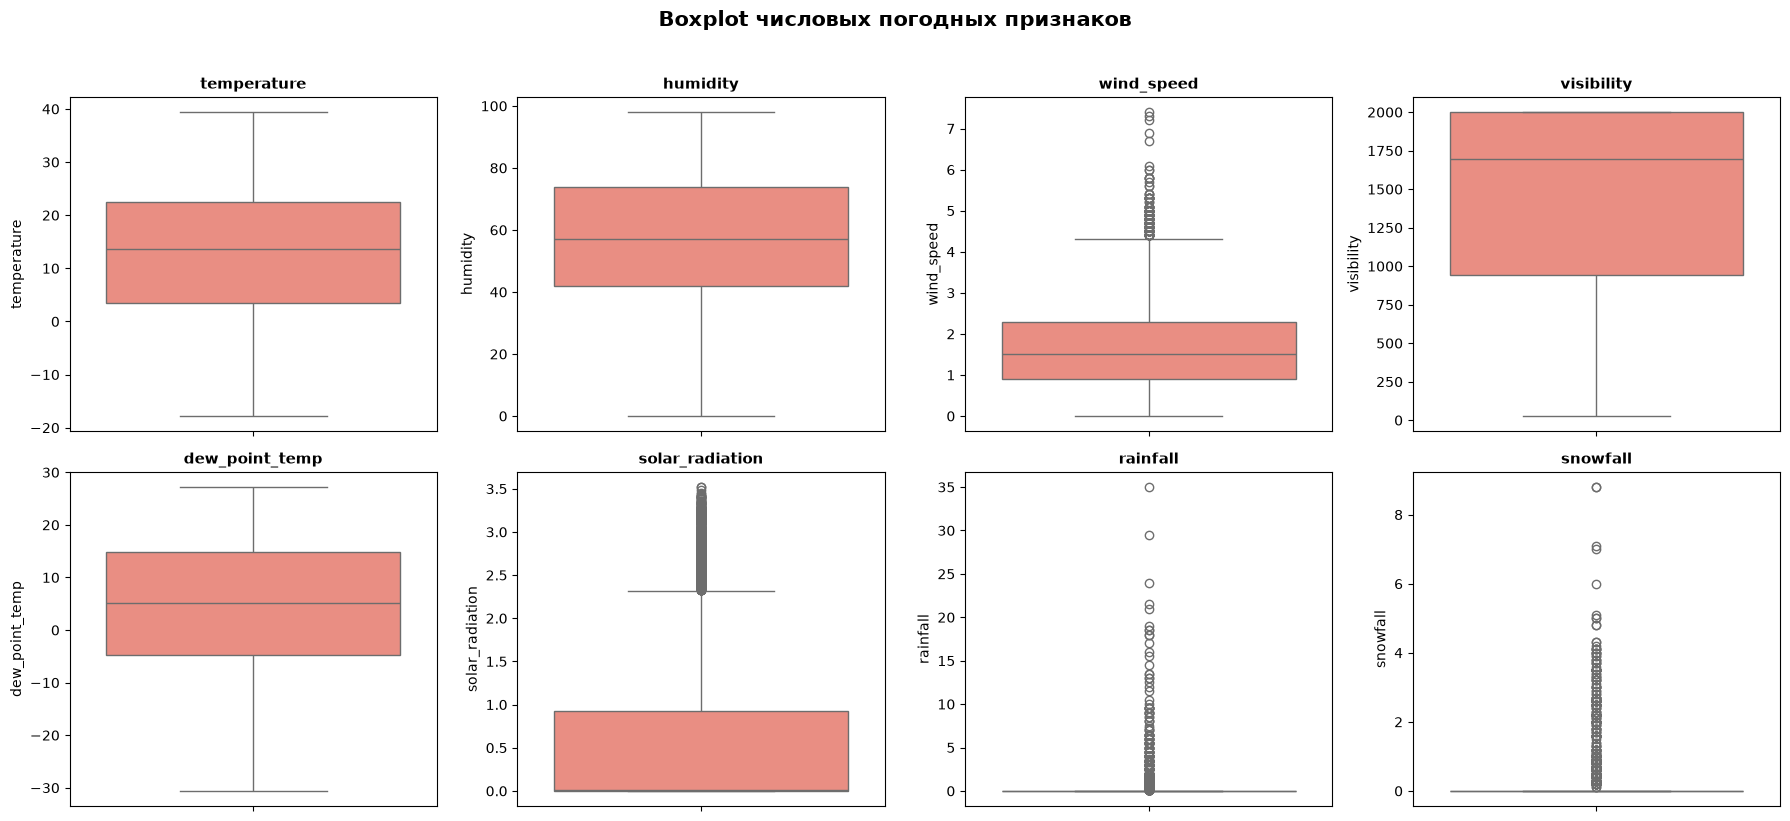

In [55]:
num_cols = [
    'temperature', 'humidity', 'wind_speed', 'visibility',
    'dew_point_temp', 'solar_radiation', 'rainfall', 'snowfall'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col, fontsize=11, fontweight='bold')

plt.suptitle('Boxplot числовых погодных признаков', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Conclusion: Boxplot for all numerical features

У `rainfall` и `snowfall` границы boxplot сжаты до нуля, а у `wind_speed` и
`solar_radiation` заметны точки выше верхнего уса. Эти точки сами по себе
не свидетельствуют об ошибках в данных. Распределения отдельных признаков
рассмотрены в следующих подразделах.

### Temperature Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 12.8829 | Медиана: 13.7000 | Std: 11.9448
Min / Max: -17.8000 / 39.4000
Q1: 3.5000 | Q3: 22.5000 | IQR: 19.0000
IQR-пороги: [-25.0000, 51.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 21 (0.24%)
Асимметрия: -0.1983 | Эксцесс: -0.8378

Процентили:
0.000   -17.800
0.001   -16.200
0.010   -12.741
0.050    -7.100
0.250     3.500
0.500    13.700
0.750    22.500
0.950    30.700
0.990    35.100
0.999    37.800
1.000    39.400
Name: temperature, dtype: float64


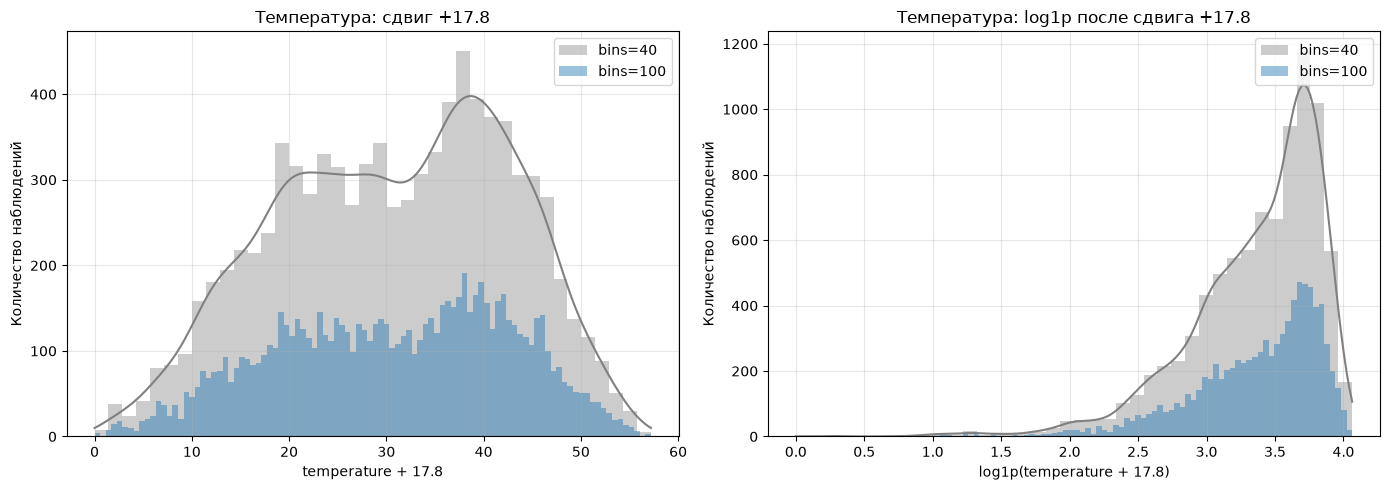

In [56]:
analyze_distribution(df["temperature"])

_ = plot_distribution_pair(
    df["temperature"] + 17.8,
    feature_name="temperature + 17.8",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
    custom_titles=(
        "Температура: сдвиг +17.8",
        "Температура: log1p после сдвига +17.8",
    ),
)

### Humidity Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 58.2263 | Медиана: 57.0000 | Std: 20.3624
Min / Max: 0.0000 / 98.0000
Q1: 42.0000 | Q3: 74.0000 | IQR: 32.0000
IQR-пороги: [-6.0000, 122.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 17 (0.19%)
Асимметрия: 0.0596 | Эксцесс: -0.8036

Процентили:
0.000     0.0
0.001     0.0
0.010    17.0
0.050    27.0
0.250    42.0
0.500    57.0
0.750    74.0
0.950    94.0
0.990    97.0
0.999    98.0
1.000    98.0
Name: humidity, dtype: float64


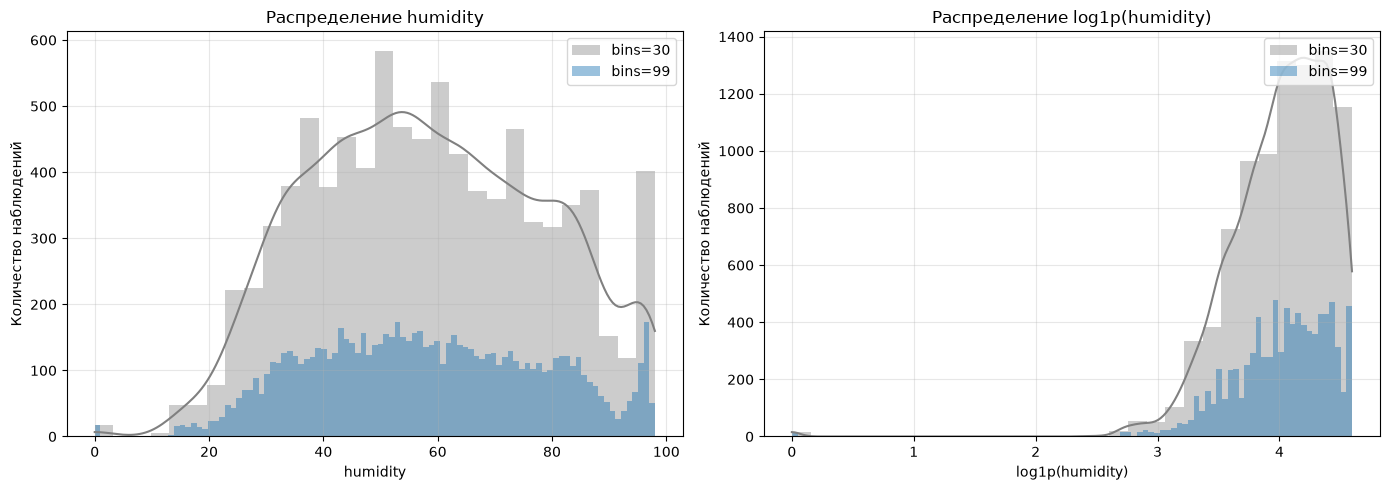

In [57]:
analyze_distribution(df["humidity"])

_ = plot_distribution_pair(
    df["humidity"],
    feature_name="humidity",
    clip_quantiles=None,
    bins=(30, 99),
    kde=True 
)

In [58]:
ctx = df[["humidity", "temperature", "dew_point_temp", "functioning_day"]].assign(
    timestamp=pd.to_datetime(df["date"]) + pd.to_timedelta(df["hour"], unit="h"),
    humidity_is_zero=df["humidity"].eq(0),
)

zero = ctx["humidity_is_zero"]
zero_hours = ctx.loc[zero, "timestamp"]
one_hour = pd.Timedelta(hours=1)
neighbors = ctx["timestamp"].isin((zero_hours - one_hour).array) | ctx[
    "timestamp"
].isin((zero_hours + one_hour).array)

print(f"Нулевая влажность: {zero.sum()} из {len(ctx)} часов ({zero.mean():.2%})")
display(ctx.loc[zero | neighbors, [
    "timestamp", "humidity", "temperature", "dew_point_temp",
    "functioning_day", "humidity_is_zero",
]].sort_values("timestamp"))

Нулевая влажность: 17 из 8760 часов (0.19%)


,timestamp,humidity,temperature,dew_point_temp,functioning_day,humidity_is_zero
4062,2018-05-19 06:00:00,70,10.5,5.2,Yes,False
4063,2018-05-19 07:00:00,0,11.4,4.5,Yes,True
4064,2018-05-19 08:00:00,57,13.7,5.3,Yes,False
4105,2018-05-21 01:00:00,31,14.5,-2.4,Yes,False
4106,2018-05-21 02:00:00,0,13.9,-2.1,Yes,True
4107,2018-05-21 03:00:00,0,13.0,-2.5,Yes,True
4108,2018-05-21 04:00:00,0,12.4,-3.4,Yes,True
4109,2018-05-21 05:00:00,0,11.9,-2.7,Yes,True
4110,2018-05-21 06:00:00,0,11.4,-2.0,Yes,True
4111,2018-05-21 07:00:00,0,12.3,-2.7,Yes,True


In [59]:
rh = df[["date", "hour", "humidity", "temperature", "dew_point_temp"]].copy()
t, td = rh["temperature"], rh["dew_point_temp"]

rh["rh_est"] = 100 * np.exp(
    17.67 * td / (td + 243.5) - 17.67 * t / (t + 243.5)
)
rh["delta_pp"] = rh["rh_est"] - rh["humidity"]
rh["abs_delta_pp"] = rh["delta_pp"].abs()

zero = rh["humidity"].eq(0)
valid = np.isfinite(t) & np.isfinite(td) & td.le(t) & rh["humidity"].between(0, 100)
nonzero = rh.loc[valid & ~zero]
round_cols = {"rh_est": 2, "delta_pp": 2, "abs_delta_pp": 2}

print("Нулевые записи: исходная и расчётная влажность")
display(rh.loc[zero].sort_values(["date", "hour"]).round(round_cols))

print("Расхождения на ненулевых записях, п.п.")
display(nonzero[["delta_pp", "abs_delta_pp"]]
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

print("15 крупнейших расхождений на ненулевых записях")
display(nonzero.nlargest(15, "abs_delta_pp").round(round_cols))

print(f"Строки с неподходящими входами или влажностью вне диапазона: {(~valid).sum()}")
if (~valid).any():
    display(rh.loc[~valid].sort_values(["date", "hour"]).head(20).round(round_cols))

Нулевые записи: исходная и расчётная влажность


,date,hour,humidity,temperature,dew_point_temp,rh_est,delta_pp,abs_delta_pp
4063,2018-05-19,7,0,11.4,4.5,62.52,62.52,62.52
4106,2018-05-21,2,0,13.9,-2.1,33.02,33.02,33.02
4107,2018-05-21,3,0,13.0,-2.5,34.00,34.00,34.00
4108,2018-05-21,4,0,12.4,-3.4,33.07,33.07,33.07
4109,2018-05-21,5,0,11.9,-2.7,36.01,36.01,36.01
4110,2018-05-21,6,0,11.4,-2.0,39.20,39.20,39.20
4111,2018-05-21,7,0,12.3,-2.7,35.07,35.07,35.07
4131,2018-05-22,3,0,15.5,10.4,71.63,71.63,71.63
4132,2018-05-22,4,0,15.6,10.5,71.65,71.65,71.65
4133,2018-05-22,5,0,15.7,10.6,71.66,71.66,71.66


Расхождения на ненулевых записях, п.п.


,delta_pp,abs_delta_pp
count,8743.00,8743.00
mean,-0.14,0.25
std,0.80,0.77
min,-33.93,0.00
50%,-0.15,0.20
90%,0.19,0.43
95%,0.27,0.50
99%,0.42,0.61
max,24.09,33.93


15 крупнейших расхождений на ненулевых записях


,date,hour,humidity,temperature,dew_point_temp,rh_est,delta_pp,abs_delta_pp
4363,2018-05-31,19,53,25.2,0.0,19.07,-33.93,33.93
4298,2018-05-29,2,56,20.2,0.0,25.83,-30.17,30.17
4297,2018-05-29,1,55,20.3,0.0,25.67,-29.33,29.33
4296,2018-05-29,0,54,20.6,0.0,25.20,-28.80,28.80
8730,2018-11-29,18,46,0.0,-4.8,70.09,24.09,24.09
4257,2018-05-27,9,43,19.5,0.0,26.98,-16.02,16.02
4402,2018-06-02,10,33,25.5,0.0,18.73,-14.27,14.27
4265,2018-05-27,17,32,23.5,0.0,21.11,-10.89,10.89
4259,2018-05-27,11,33,22.3,0.0,22.71,-10.29,10.29
4258,2018-05-27,10,33,21.6,0.0,23.70,-9.30,9.30


Строки с неподходящими входами или влажностью вне диапазона: 0


### Conclusion: Humidity Overview

На графике частот отдельных значений влажности заметен локальный пик
на 97 %.

По температуре воздуха и точке росы рассчитали относительную влажность
и сравнили её с записанной. Для 8 743 ненулевых записей медианное абсолютное
расхождение составило 0,20 п.п., а 99-й перцентиль — 0,61 п.п.
Для всех 17 нулевых записей расчёт дал от 33,02 до 71,66 %.

Причина нулей возможна в ошибке прибора или измерения. Исходный столбец сохраняем в baseline;
замену только нулевых записей расчётными значениями проверяем отдельно
на тех же временных фолдах. Крупные расхождения среди ненулевых записей
отмечны для проверки.

### Wind Speed Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1.7249 | Медиана: 1.5000 | Std: 1.0363
Min / Max: 0.0000 / 7.4000
Q1: 0.9000 | Q3: 2.3000 | IQR: 1.4000
IQR-пороги: [-1.2000, 4.4000]
За IQR-порогами: 161 (1.84%) | Ниже: 0 | Выше: 161
Нули: 74 (0.84%)
Асимметрия: 0.8910 | Эксцесс: 0.7272

Процентили:
0.000    0.0
0.001    0.0
0.010    0.1
0.050    0.4
0.250    0.9
0.500    1.5
0.750    2.3
0.950    3.7
0.990    4.7
0.999    5.8
1.000    7.4
Name: wind_speed, dtype: float64


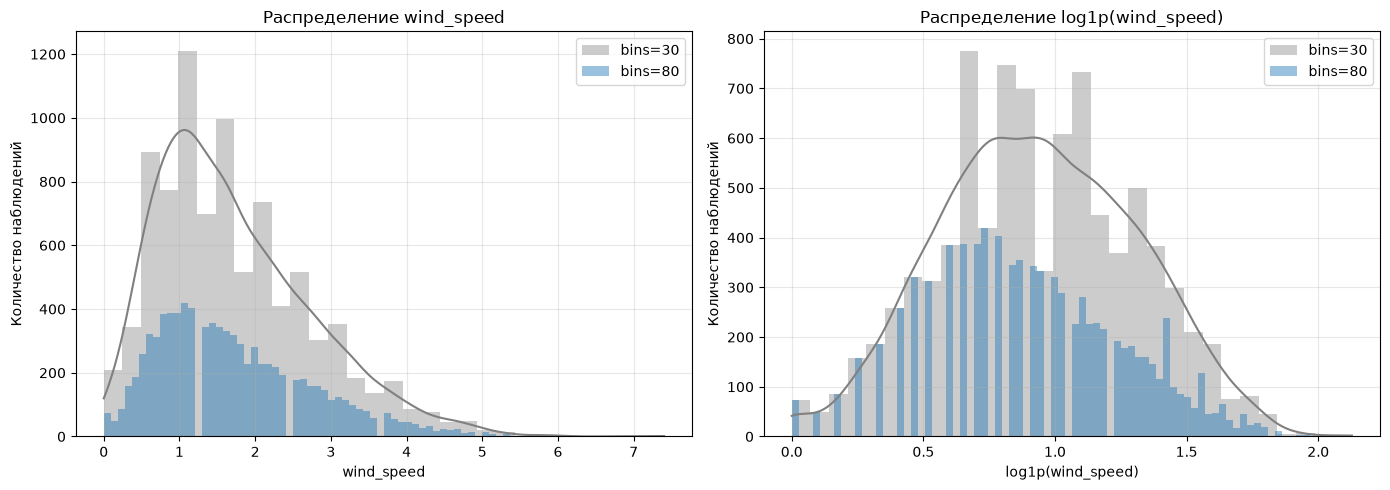

In [60]:
analyze_distribution(df["wind_speed"])

_ = plot_distribution_pair(
    df["wind_speed"],
    feature_name="wind_speed",
    clip_quantiles=None,
    bins=(30, 80),
    kde=True,
)

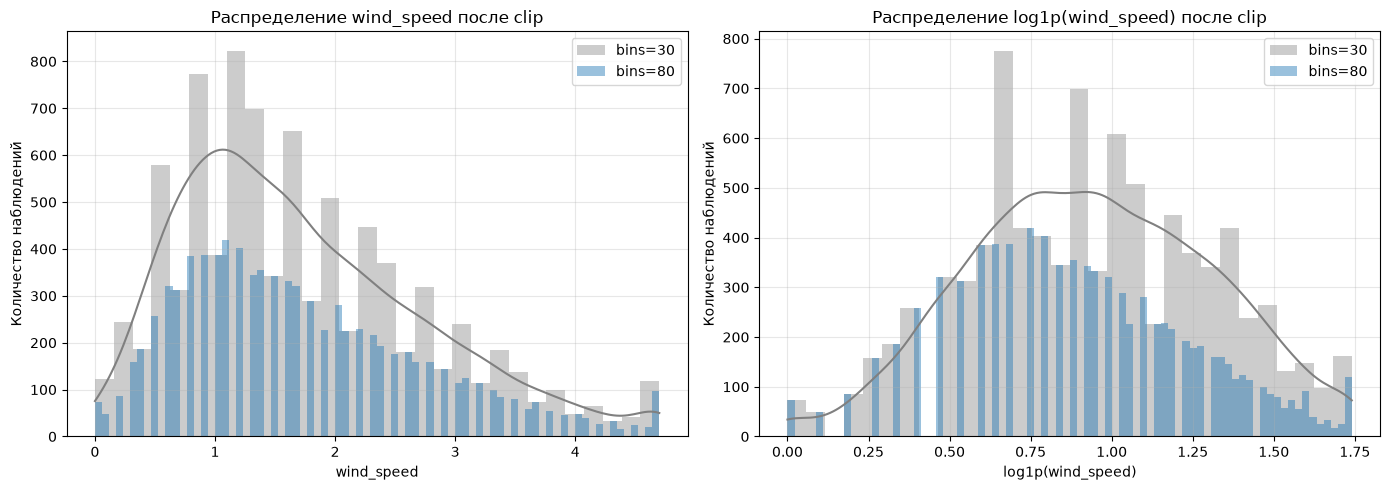

In [61]:
_ = plot_distribution_pair(
    df["wind_speed"],
    feature_name="wind_speed",
    clip_quantiles=(0.0, 0.99),
    bins=(30, 80),
    kde=True,
)

In [62]:
wind_counts = df["wind_speed"].value_counts().sort_index()
print("Уникальных значений:", wind_counts.size)
display(wind_counts.sort_values(ascending=False).head(15))

wind_steps = wind_counts.index.to_series().diff().dropna().round(6)
display(wind_steps.value_counts().head(10))

Уникальных значений: 65


wind_speed
1.1    420
1.2    403
0.9    388
1.0    388
0.8    385
1.4    355
1.3    344
1.5    343
1.6    332
0.6    321
1.7    320
0.7    313
1.8    289
2.0    281
0.5    258
Name: count, dtype: int64

wind_speed
0.1    59
0.2     3
0.6     1
0.3     1
Name: count, dtype: int64

### Conclusion: Wind Speed Overview

У `wind_speed` 65 уникальных значений; большинство соседних значений
различаются на 0,1 м/с. Дискретный шаг записи объясняет пустые интервалы
на мелкой гистограмме. В baseline используем исходный `wind_speed` как числовой
признак без `clip` и `log1p`.

### Visibility Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1436.8258 | Медиана: 1698.0000 | Std: 608.2987
Min / Max: 27.0000 / 2000.0000
Q1: 940.0000 | Q3: 2000.0000 | IQR: 1060.0000
IQR-пороги: [-650.0000, 3590.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 0 (0.00%)
Асимметрия: -0.7018 | Эксцесс: -0.9620

Процентили:
0.000      27.0
0.001      66.0
0.010     173.0
0.050     300.0
0.250     940.0
0.500    1698.0
0.750    2000.0
0.950    2000.0
0.990    2000.0
0.999    2000.0
1.000    2000.0
Name: visibility, dtype: float64


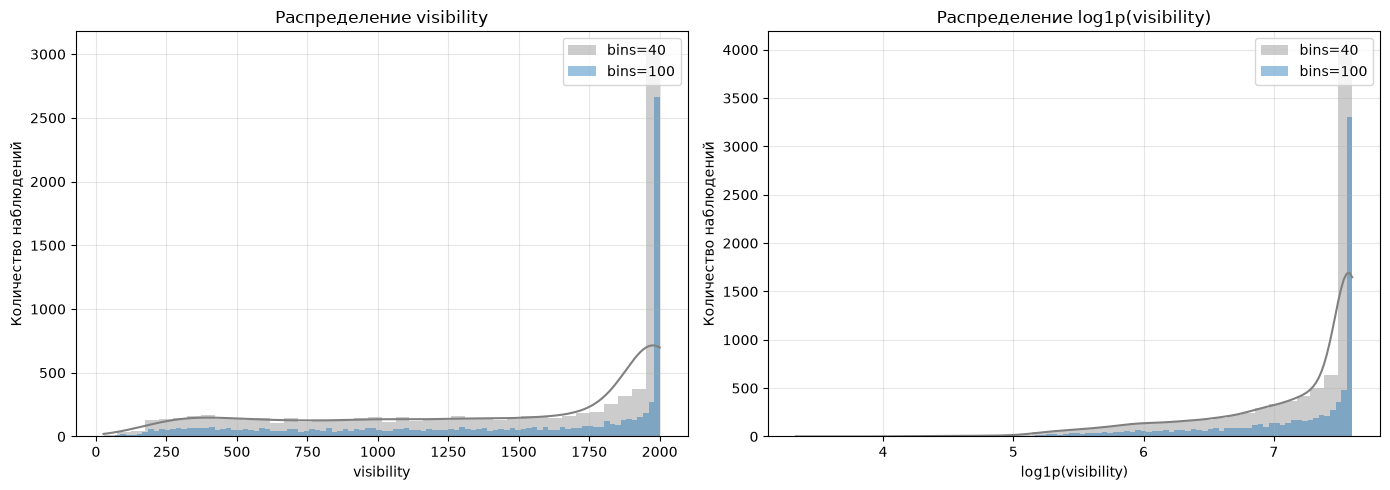

Видимость равна 2000 в 2245 строках (25.63% от всех строк).


In [63]:
analyze_distribution(df["visibility"])

_ = plot_distribution_pair(
    df["visibility"],
    feature_name="visibility",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
)
at_max = df["visibility"].eq(2000)
print(f"Видимость равна 2000 в {at_max.sum()} строках ({at_max.mean():.2%} от всех строк).")

Всего: 6,515 | В анализе: 6,515
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 1242.7619 | Медиана: 1319.0000 | Std: 592.0974
Min / Max: 27.0000 / 1999.0000
Q1: 712.5000 | Q3: 1819.5000 | IQR: 1107.0000
IQR-пороги: [-948.0000, 3480.0000]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 0 (0.00%)
Асимметрия: -0.3012 | Эксцесс: -1.2804

Процентили:
0.000      27.000
0.001      61.056
0.010     153.280
0.050     263.700
0.250     712.500
0.500    1319.000
0.750    1819.500
0.950    1985.000
0.990    1997.000
0.999    1999.000
1.000    1999.000
Name: visibility, dtype: float64


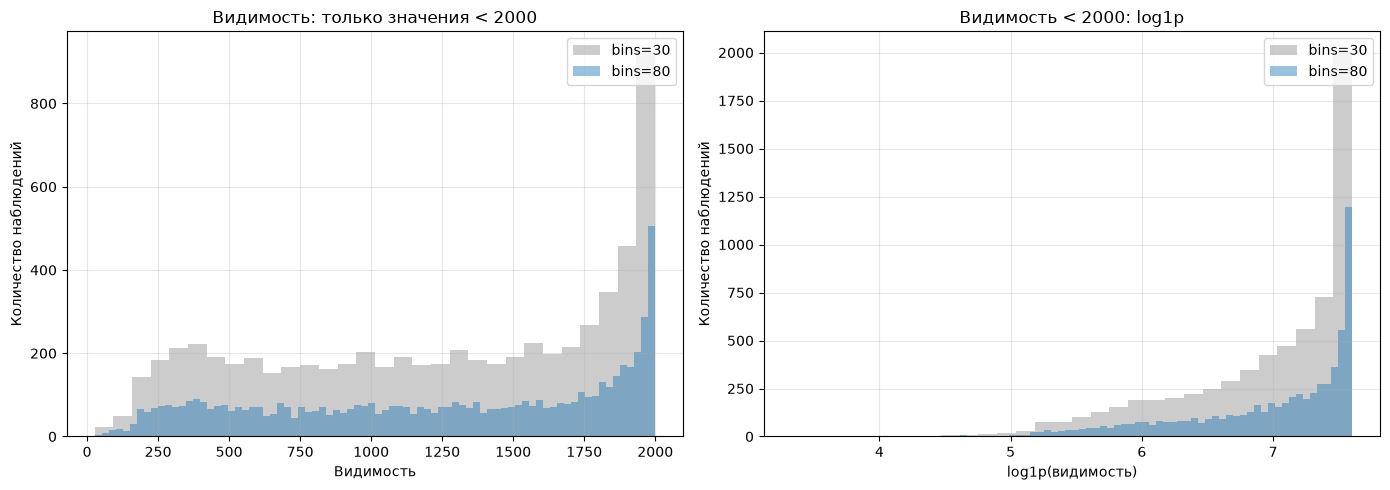

In [64]:
visibility = df["visibility"]
visibility_below_2000 = visibility[visibility < 2000]

analyze_distribution(visibility_below_2000)

_ = plot_distribution_pair(
    visibility_below_2000,
    feature_name="visibility < 2000",
    clip_quantiles=None,
    bins=(30, 80),
    kde=False,
    custom_titles=(
        "Видимость: только значения < 2000",
        "Видимость < 2000: log1p",
    ),
    custom_xlabels=(
        "Видимость",
        "log1p(видимость)",
    ),
)

### Dew Point Temp Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 4.0738 | Медиана: 5.1000 | Std: 13.0604
Min / Max: -30.6000 / 27.2000
Q1: -4.7000 | Q3: 14.8000 | IQR: 19.5000
IQR-пороги: [-33.9500, 44.0500]
За IQR-порогами: 0 (0.00%) | Ниже: 0 | Выше: 0
Нули: 60 (0.68%)
Асимметрия: -0.3673 | Эксцесс: -0.7554

Процентили:
0.000   -30.6000
0.001   -29.0241
0.010   -24.8000
0.050   -19.5050
0.250    -4.7000
0.500     5.1000
0.750    14.8000
0.950    22.4050
0.990    24.7000
0.999    26.0000
1.000    27.2000
Name: dew_point_temp, dtype: float64


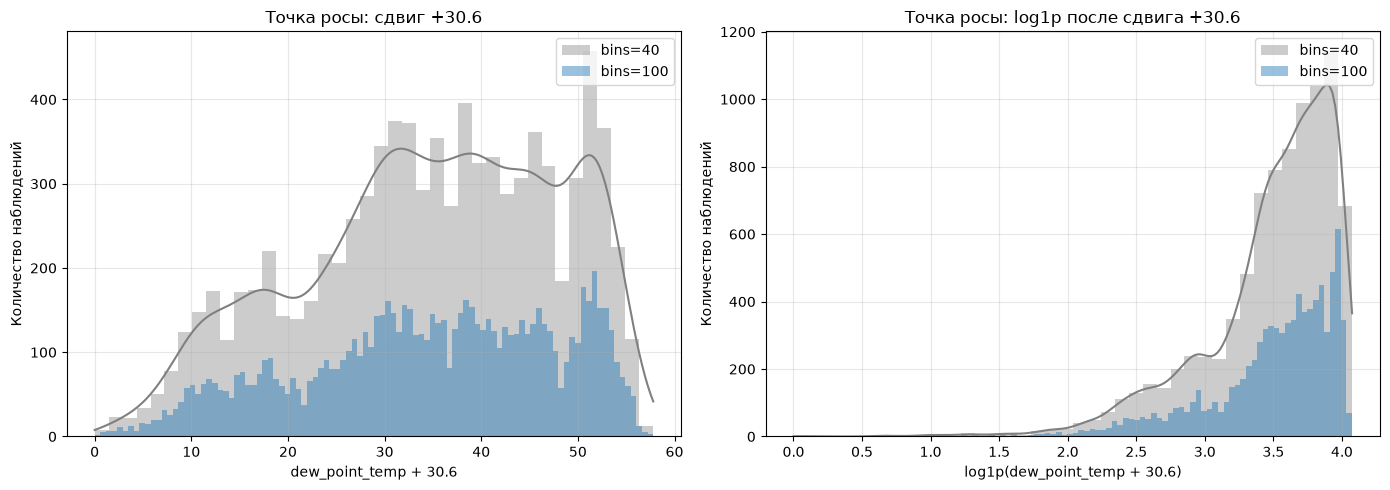

In [65]:
analyze_distribution(df["dew_point_temp"])

_ = plot_distribution_pair(
    df["dew_point_temp"] + 30.6,
    feature_name="dew_point_temp + 30.6",
    clip_quantiles=None,
    bins=(40, 100),
    kde=True,
    custom_titles=(
        "Точка росы: сдвиг +30.6",
        "Точка росы: log1p после сдвига +30.6",
    ),
)

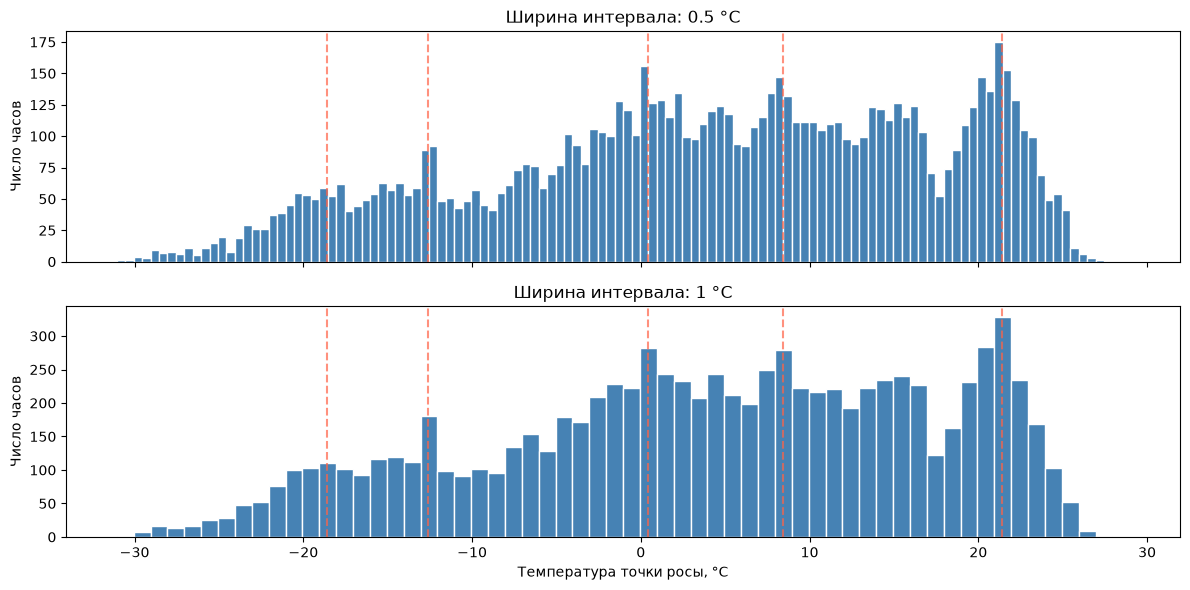


Окрестность -18.6 °C (±1 °C): самые частые значения


dew_point_temp
-17.6    18
-17.7    15
-19.0    14
-18.6    14
-19.1    13
Name: Число часов, dtype: int64


Окрестность -12.6 °C (±1 °C): самые частые значения


dew_point_temp
-12.9    28
-12.6    21
-12.3    21
-12.1    20
-12.4    18
Name: Число часов, dtype: int64


Окрестность 0.4 °C (±1 °C): самые частые значения


dew_point_temp
0.0    60
1.3    33
1.1    31
0.4    29
1.2    29
Name: Число часов, dtype: int64


Окрестность 8.4 °C (±1 °C): самые частые значения


dew_point_temp
8.9    39
7.9    32
7.5    31
8.1    30
8.2    30
Name: Число часов, dtype: int64


Окрестность 21.4 °C (±1 °C): самые частые значения


dew_point_temp
21.1    43
21.2    40
21.8    39
21.3    38
21.5    36
Name: Число часов, dtype: int64

In [66]:
dew = df["dew_point_temp"].dropna()
candidates = np.array([12, 18, 31, 39, 52]) - 30.6

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, width in zip(axes, [0.5, 1.0]):
    edges = np.arange(
        np.floor(dew.min()) - 0.05,
        np.ceil(dew.max()) + width,
        width,
    )
    ax.hist(dew, bins=edges, color="steelblue", edgecolor="white")
    for x in candidates:
        ax.axvline(x, color="tomato", linestyle="--", alpha=0.7)
    ax.set(title=f"Ширина интервала: {width:g} °C", ylabel="Число часов")

axes[-1].set_xlabel("Температура точки росы, °C")
fig.tight_layout()
plt.show()

counts = dew.value_counts().sort_index()
for x in candidates:
    nearby = counts.loc[counts.index.to_series().between(x - 1, x + 1)]
    print(f"\nОкрестность {x:.1f} °C (±1 °C): самые частые значения")
    display(nearby.nlargest(5).rename("Число часов"))

### Conclusion: Dew Point Temp Overview

Локальные пики около −12,6, 0, 8,4 и 21,4 °C видны на гистограммах
с шириной интервала 0,5 и 1 °C. Отдельно выделяется значение 0 °C:
оно встречается в 60 часах, и часть этих записей совпадает с крупными
расхождениями между записанной и расчётной влажностью. В baseline оставляем исходную точку росы.

### Solar Radiation Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.5691 | Медиана: 0.0100 | Std: 0.8687
Min / Max: 0.0000 / 3.5200
Q1: 0.0000 | Q3: 0.9300 | IQR: 0.9300
IQR-пороги: [-1.3950, 2.3250]
За IQR-порогами: 641 (7.32%) | Ниже: 0 | Выше: 641
Нули: 4,300 (49.09%)
Асимметрия: 1.5040 | Эксцесс: 1.1264

Процентили:
0.000    0.0000
0.001    0.0000
0.010    0.0000
0.050    0.0000
0.250    0.0000
0.500    0.0100
0.750    0.9300
0.950    2.5600
0.990    3.1700
0.999    3.4124
1.000    3.5200
Name: solar_radiation, dtype: float64


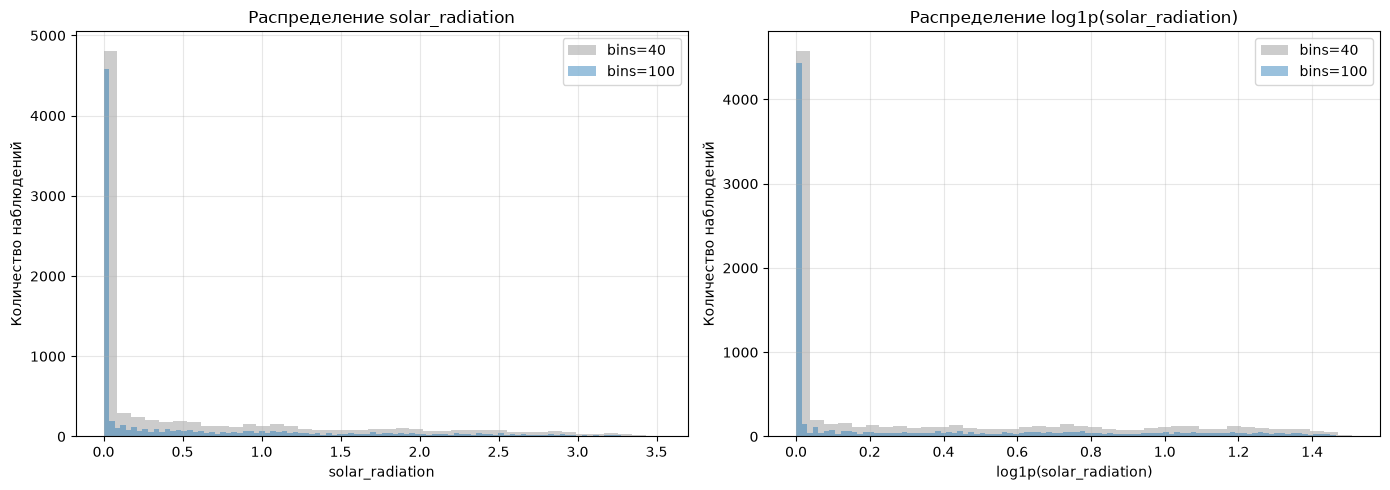

In [67]:
analyze_distribution(df["solar_radiation"])

_ = plot_distribution_pair(
    df["solar_radiation"],
    feature_name="solar_radiation",
    clip_quantiles=None,
    bins=(40, 100),
    kde=False,
)

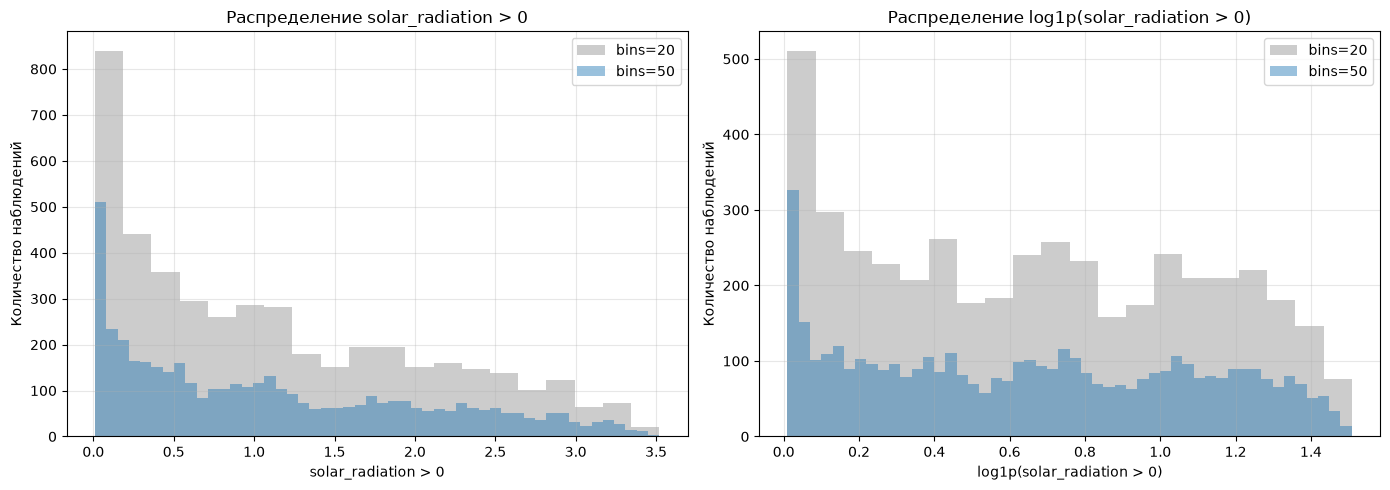

In [68]:
_ = plot_distribution_pair(
    df.loc[df["solar_radiation"] > 0, "solar_radiation"],
    feature_name="solar_radiation > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

### Rainfall Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.1487 | Медиана: 0.0000 | Std: 1.1282
Min / Max: 0.0000 / 35.0000
Q1: 0.0000 | Q3: 0.0000 | IQR: 0.0000
IQR-пороги: [0.0000, 0.0000]
За IQR-порогами: 528 (6.03%) | Ниже: 0 | Выше: 528
Нули: 8,232 (93.97%)
Асимметрия: 14.5332 | Эксцесс: 284.9911
Внимание: IQR = 0. Пороги совпадают; выход за них не означает ошибку данных.

Процентили:
0.000     0.0
0.001     0.0
0.010     0.0
0.050     0.0
0.250     0.0
0.500     0.0
0.750     0.0
0.950     0.4
0.990     4.0
0.999    18.0
1.000    35.0
Name: rainfall, dtype: float64


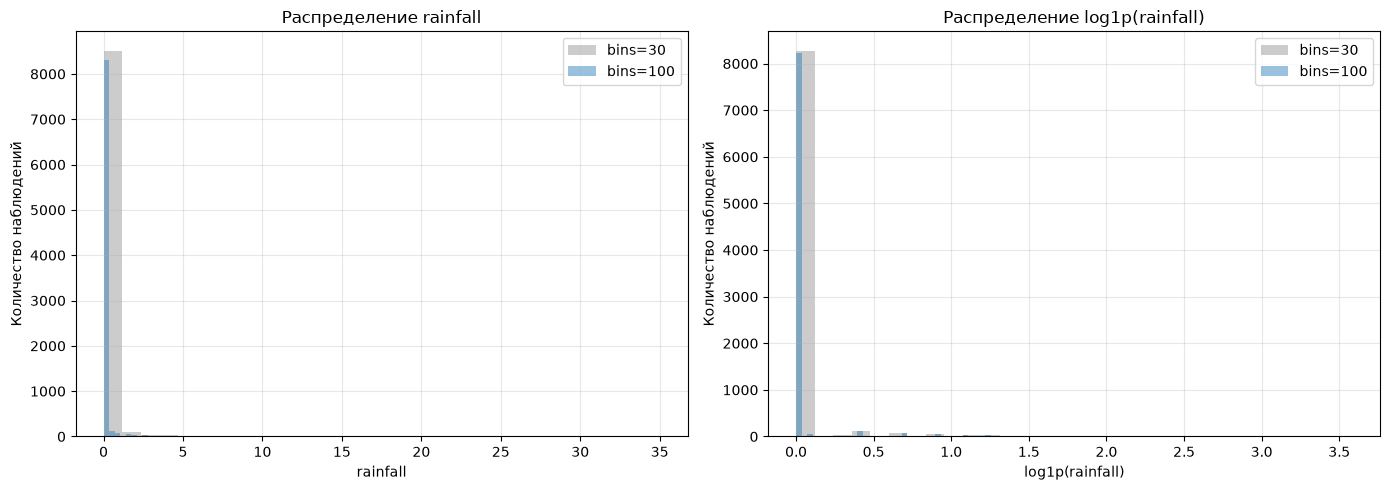

In [69]:
analyze_distribution(df["rainfall"])

_ = plot_distribution_pair(
    df["rainfall"],
    feature_name="rainfall",
    clip_quantiles=None,
    bins=(30, 100),
    kde=False,
)

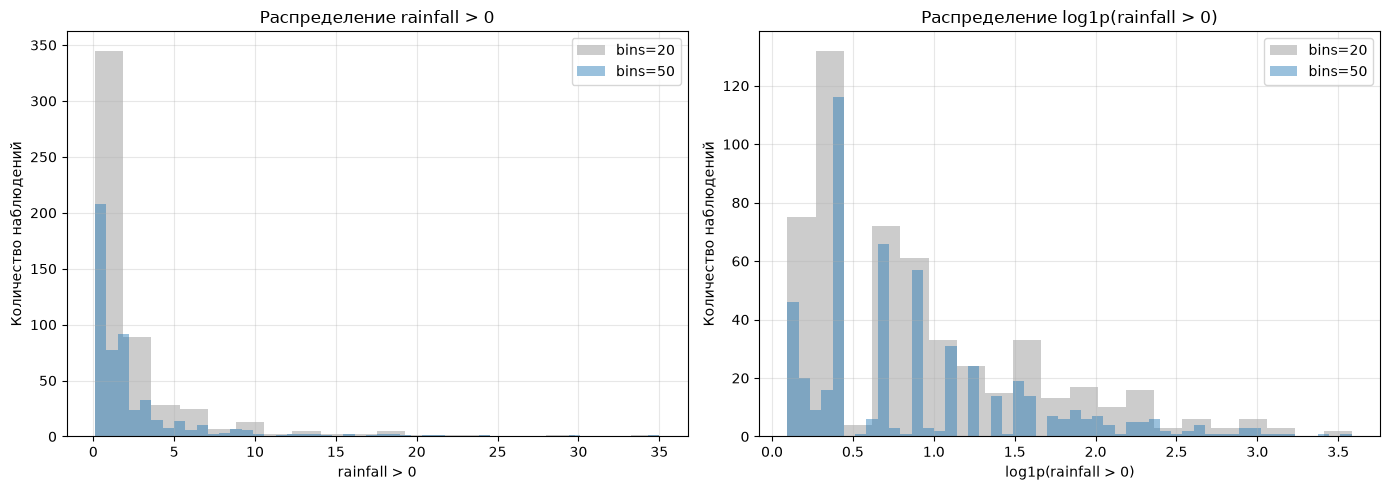

In [70]:
_ = plot_distribution_pair(
    df.loc[df["rainfall"] > 0, "rainfall"],
    feature_name="rainfall > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

### Snowfall Overview
[Индекс численных фичей](#Numerical-Features-Index)

Всего: 8,760 | В анализе: 8,760
Пропуски: 0 (0.00%) | Бесконечности: 0 (0.00%)
Среднее: 0.0751 | Медиана: 0.0000 | Std: 0.4367
Min / Max: 0.0000 / 8.8000
Q1: 0.0000 | Q3: 0.0000 | IQR: 0.0000
IQR-пороги: [0.0000, 0.0000]
За IQR-порогами: 443 (5.06%) | Ниже: 0 | Выше: 443
Нули: 8,317 (94.94%)
Асимметрия: 8.4408 | Эксцесс: 93.8033
Внимание: IQR = 0. Пороги совпадают; выход за них не означает ошибку данных.

Процентили:
0.000    0.0
0.001    0.0
0.010    0.0
0.050    0.0
0.250    0.0
0.500    0.0
0.750    0.0
0.950    0.2
0.990    2.5
0.999    4.8
1.000    8.8
Name: snowfall, dtype: float64


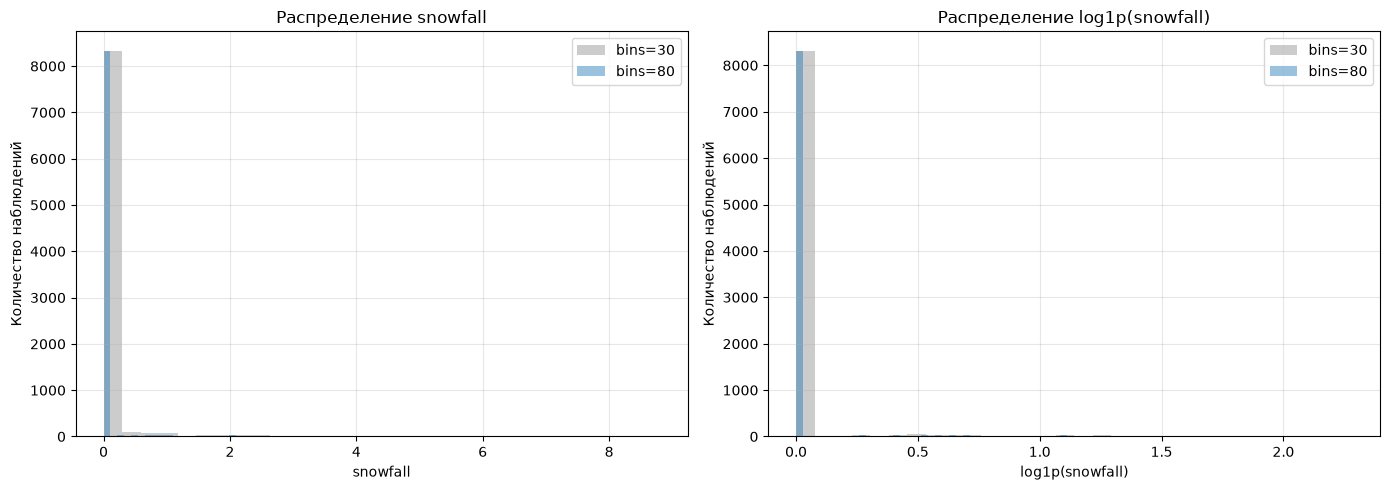

In [71]:
analyze_distribution(df["snowfall"])

_ = plot_distribution_pair(
    df["snowfall"],
    feature_name="snowfall",
    clip_quantiles=None,
    bins=(30, 80),
    kde=False,
)

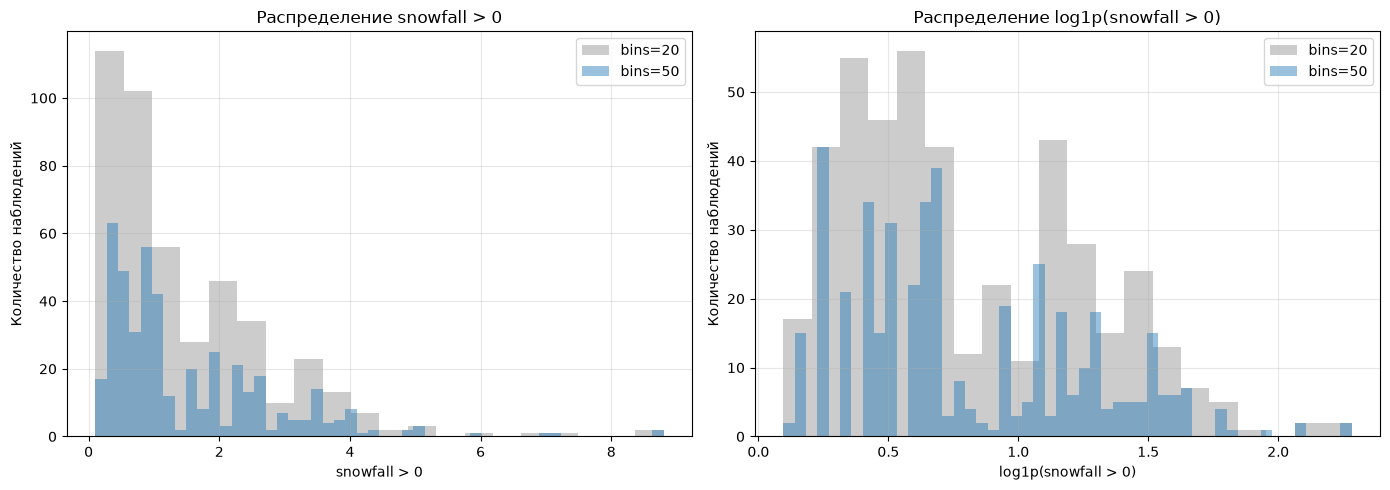

In [72]:
_ = plot_distribution_pair(
    df.loc[df["snowfall"] > 0, "snowfall"],
    feature_name="snowfall > 0",
    clip_quantiles=None,
    bins=(20, 50),
    kde=False,
)

| Признак | Что означает | Пропуски | Пики / скопления | Значения за IQR-порогами | Асимметрия | Клипирование в baseline | Нужен флаг? | Резюме по признаку |
|---|---|---|---|---|---|---|---|---|
| `temperature` | Температура воздуха, °C | Нет | Нет | Нет | Слабая левосторонняя, skew = −0.20 | Нет | Нет | Диапазон от −17.8 до 39.4 °C. Сохранить исходные значения; сдвиг `+17.8` использовался только на сравнительном графике с `log1p`. |
| `humidity` | Относительная влажность, % | Нет, но есть 17 нулей подозрительных на ошибку измерения, можно заменить на расчетное значение | Локальный пик на 97 % на графике частот точных значений | Нет | Близкая к нулю, skew = 0.06 | Нет | Нет | Сохранить исходный признак. Причина 17 нулевых значений (0.19 %) не установлена; не заменять их без основания. Связь пика на 97 % с числом аренд не проверялась. |
| `wind_speed` | Скорость ветра, м/с | Нет | 65 уникальных значений; большинство соседних уникальных значений различаются на 0.1 м/с. Нулей 0.84 % | 161 значение (1.84 %) выше верхнего порога | Правосторонняя, skew = 0.89 | Нет. Отдельно проверить ограничение верхнего хвоста по 99-му перцентилю. | Нет | Сохранить wind_speed числовым признаком. Большинство соседних наблюдаемых скоростей различаются на 0,1 м/с, поэтому на мелкой гистограмме видны пустые интервалы. Правый хвост до 7,4 м/с оставить в baseline; вариант с клипированием проверить на тех же временных фолдах. |
| `visibility` | Видимость в единицах по 10 м (т.е. 2000 = 20 км)  | Нет | Скопление на наблюдаемом максимуме 2000; Q3 = 2000; Видимость равна 2000 в 2245 строках (25.63% от всех строк).| Нет | Левосторонняя, skew = −0.70 | Нет | Да, проверить `visibility == 2000` | Сохранить исходный признак. Долю значений на максимуме вывести явно. Срез `visibility < 2000` уже рассмотрен отдельно; он не подтверждает, что 2000 — предел датчика. |
| `dew_point_temp` | Температура точки росы, °C | Нет | Локальные пики около −12,6, 0, 8,4 и 21,4 °C | Нет | Слабая левосторонняя, skew = −0.37 | Нет | Нет | Диапазон от −30.6 до 27.2 °C. Сохранить исходные значения; сдвиг `+30.6` использовался только на сравнительном графике с `log1p`. |
| `solar_radiation` | Солнечная радиация, МДж/м² | Нет | 4300 нулей (49.09 %) | 641 значение (7.32 %) выше верхнего порога | Правосторонняя, skew = 1.50 | Проверить ограничение верхнего хвоста по 99-му перцентилю. | Да, проверить `solar_radiation > 0` | В baseline сохранить исходную величину. Отдельно проверить флаг solar_radiation > 0 и клипирование верхнего хвоста. Флаг обозначает положительное значение радиации.
 |
| `rainfall` | Количество осадков в виде дождя, мм| Нет | 8232 нуля (93.97 %) | 528 значений (6.03 %). При IQR = 0 верхний порог равен нулю, поэтому за ним все положительные значения | Сильная правосторонняя, skew = 14.53 | Нет | Да, проверить `rainfall > 0` | Сохранить нули и исходную величину осадков. График для `rainfall > 0` — диагностический срез, не фильтр для обучения. |
| `snowfall` | Количество осадков в виде снега, см | Нет | 8317 нулей (94.94 %) | 443 значения (5.06 %). При IQR = 0 верхний порог равен нулю, поэтому за ним все положительные значения | Сильная правосторонняя, skew = 8.44 | Нет | Да, проверить `snowfall > 0` | Сохранить нули и исходную величину. Флаг означает положительное значение поля, а не обязательно снегопад в этот час. |

## Categorical Features and Target
[Table of Contents](#Table-of-Contents)

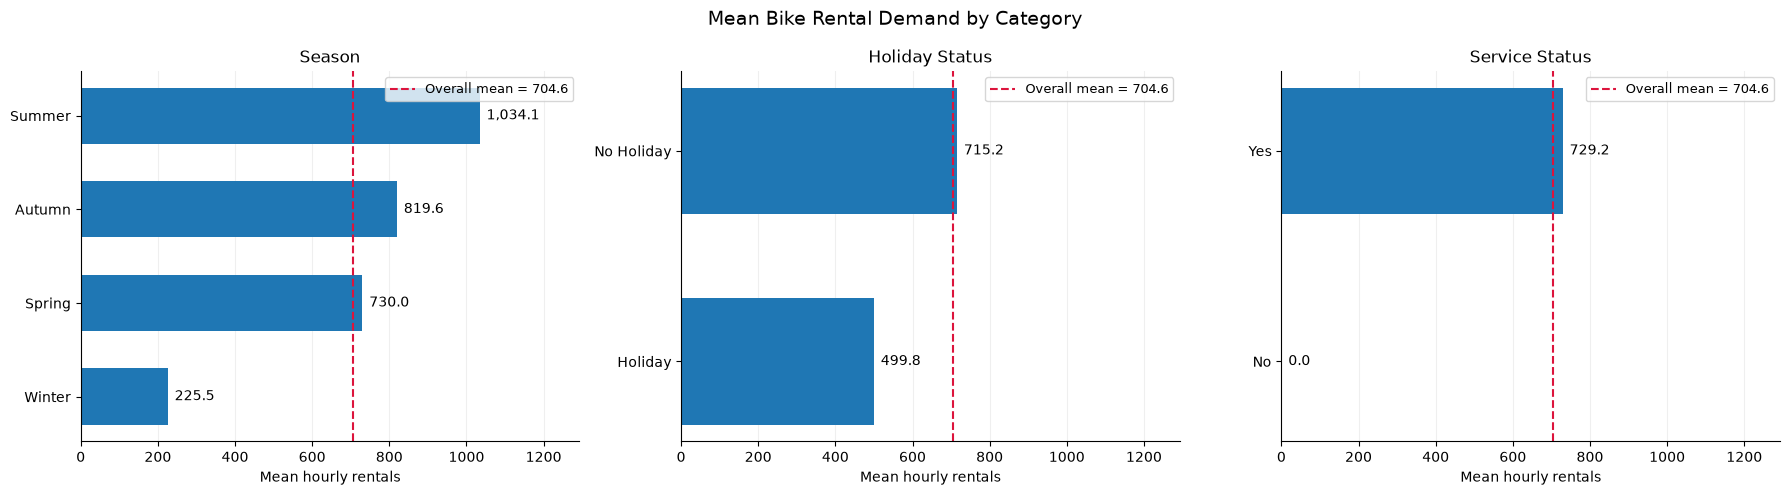


SERVICE DOWNTIME CHECK
Нерабочих часов: 295
Из них с нулевыми арендами: 295
Из них с пропущенным таргетом: 0
Во всех наблюдаемых нерабочих часах количество аренд равно 0.

seasons


,n,mean,median,std,share_pct
seasons,,,,,
Autumn,2184,819.60,763.5,651.09,24.93
Spring,2208,730.03,583.0,621.51,25.21
Summer,2208,1034.07,905.5,690.24,25.21
Winter,2160,225.54,203.0,150.37,24.66



holiday


,n,mean,median,std,share_pct
holiday,,,,,
Holiday,432,499.76,240.0,570.77,4.93
No Holiday,8328,715.23,524.5,646.88,95.07



functioning_day


,n,mean,median,std,share_pct
functioning_day,,,,,
No,295,0.00,0.0,0.00,3.37
Yes,8465,729.16,542.0,642.35,96.63


In [73]:
CAT_COLS = ["seasons", "holiday", "functioning_day"]
TARGET_COL = "rented_bike_count"
TITLES = {
    "seasons": "Season",
    "holiday": "Holiday Status",
    "functioning_day": "Service Status",
}


def compute_category_stats(df, cat_cols=CAT_COLS, target_col=TARGET_COL):
    stats = {}
    for col in cat_cols:
        s = (
            df.groupby(col, observed=True)[target_col]
              .agg(n="size", mean="mean", median="median", std="std")
        )
        s["share_pct"] = s["n"] / len(df) * 100
        stats[col] = s
    return stats


def plot_category_means(category_stats, baseline,
                        titles=TITLES, cat_cols=CAT_COLS):
    fig, axes = plt.subplots(1, len(cat_cols),
                             figsize=(6 * len(cat_cols), 5), sharex=True)
    x_max = max(
        max(s["mean"].max() for s in category_stats.values()),
        baseline,
    ) * 1.25

    for ax, col in zip(axes, cat_cols):
        means = category_stats[col]["mean"].dropna().sort_values(ascending=False)
        positions = np.arange(len(means))

        bars = ax.barh(positions, means.to_numpy(), color="tab:blue", height=0.6)
        ax.set_yticks(positions)
        ax.set_yticklabels(means.index.astype(str))
        ax.invert_yaxis()
        ax.axvline(baseline, color="crimson", linestyle="--", linewidth=1.5,
                   label=f"Overall mean = {baseline:,.1f}")
        ax.bar_label(bars, labels=[f"{v:,.1f}" for v in means],
                     padding=5, fontsize=10)

        ax.set_title(titles[col], fontsize=12)
        ax.set_xlabel("Mean hourly rentals")
        ax.set_xlim(0, x_max)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(loc="upper right", fontsize=9)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle("Mean Bike Rental Demand by Category", fontsize=14)
    fig.tight_layout()
    plt.show()


def check_service_downtime(df, col="functioning_day", target_col=TARGET_COL):
    non_func = df.loc[df[col].eq("No"), target_col]
    print("\nSERVICE DOWNTIME CHECK")
    print(f"Нерабочих часов: {len(non_func):,}")
    print(f"Из них с нулевыми арендами: {non_func.eq(0).sum():,}")
    print(f"Из них с пропущенным таргетом: {non_func.isna().sum():,}")
    if not non_func.empty and non_func.notna().all() and non_func.eq(0).all():
        print("Во всех наблюдаемых нерабочих часах количество аренд равно 0.")
    return non_func


# ---- основной скрипт ----
baseline = df[TARGET_COL].mean()
category_stats = compute_category_stats(df)

plot_category_means(category_stats, baseline)
check_service_downtime(df)

for col, stats in category_stats.items():
    print(f"\n{col}")
    display(stats.round(2))

| Колонка   | Что означает                                                                                         | Пример: осень (Autumn) |
| --------- | ---------------------------------------------------------------------------------------------------- | ---------------------- |
| n         | Сколько часов попало в группу                                                                        | 2 184 часа             |
| mean      | Среднее число аренд за час                                                                           | 819,60                 |
| median    | Медиана числа аренд за час: как минимум половина значений не выше неё и как минимум половина не ниже | 763,5                  |
| std       | Стандартное отклонение: насколько число аренд различается от часа к часу внутри сезона               | 651,09                 |
| share_pct | Доля часов этого сезона от всех строк датасета, не доля аренд                                        | 24,93%                 |

### Conclusion: Categorical Features and Target

По всем часам датасета, включая часы закрытия сервиса, среднее и медианное
число аренд за час выше всего летом и ниже всего зимой. В праздничные часы
оба показателя ниже, чем в непраздничные, но праздничная группа заметно
меньше.

Во всех 295 часах со статусом `functioning_day == "No"` число аренд равно
нулю. В baseline сохраняем все строки и используем исходные признаки
`seasons`, `holiday` и `functioning_day`.

## Feature Correlations
[Table of Contents](#Table-of-Contents)

In [74]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


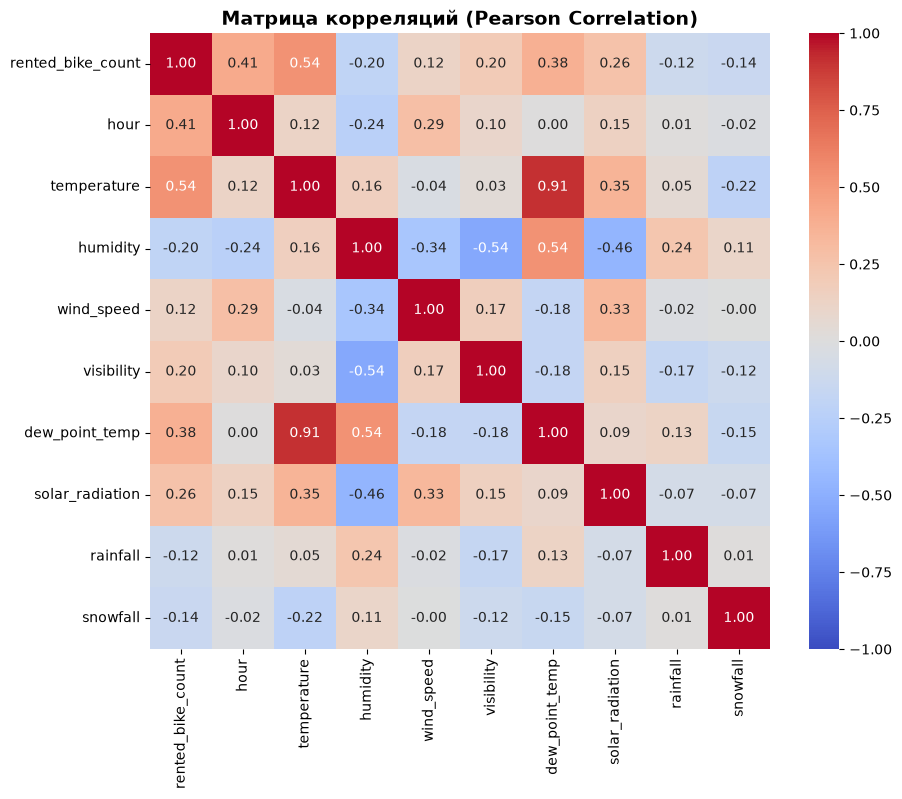

In [75]:
plt.figure(figsize=(10, 8))

corr = df.select_dtypes(include=['float64', 'int64']).corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляций (Pearson Correlation)', fontsize=14, fontweight='bold')
plt.show()

In [76]:
corr

,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temp,solar_radiation,rainfall,snowfall
rented_bike_count,1.000000,0.410257,0.538558,-0.199780,0.121108,0.199280,0.379788,0.261837,-0.123074,-0.141804
hour,0.410257,1.000000,0.124114,-0.241644,0.285197,0.098753,0.003054,0.145131,0.008715,-0.021516
temperature,0.538558,0.124114,1.000000,0.159371,-0.036252,0.034794,0.912798,0.353505,0.050282,-0.218405
humidity,-0.199780,-0.241644,0.159371,1.000000,-0.336683,-0.543090,0.536894,-0.461919,0.236397,0.108183
wind_speed,0.121108,0.285197,-0.036252,-0.336683,1.000000,0.171507,-0.176486,0.332274,-0.019674,-0.003554
visibility,0.199280,0.098753,0.034794,-0.543090,0.171507,1.000000,-0.176630,0.149738,-0.167629,-0.121695
dew_point_temp,0.379788,0.003054,0.912798,0.536894,-0.176486,-0.176630,1.000000,0.094381,0.125597,-0.150887
solar_radiation,0.261837,0.145131,0.353505,-0.461919,0.332274,0.149738,0.094381,1.000000,-0.074290,-0.072301
rainfall,-0.123074,0.008715,0.050282,0.236397,-0.019674,-0.167629,0.125597,-0.074290,1.000000,0.008500
snowfall,-0.141804,-0.021516,-0.218405,0.108183,-0.003554,-0.121695,-0.150887,-0.072301,0.008500,1.000000


### Feature Dependencies — Phi-K Correlation

Анализ попарных зависимостей числовых и категориальных переменных.
Phi-K используется для выявления в том числе нелинейных связей.

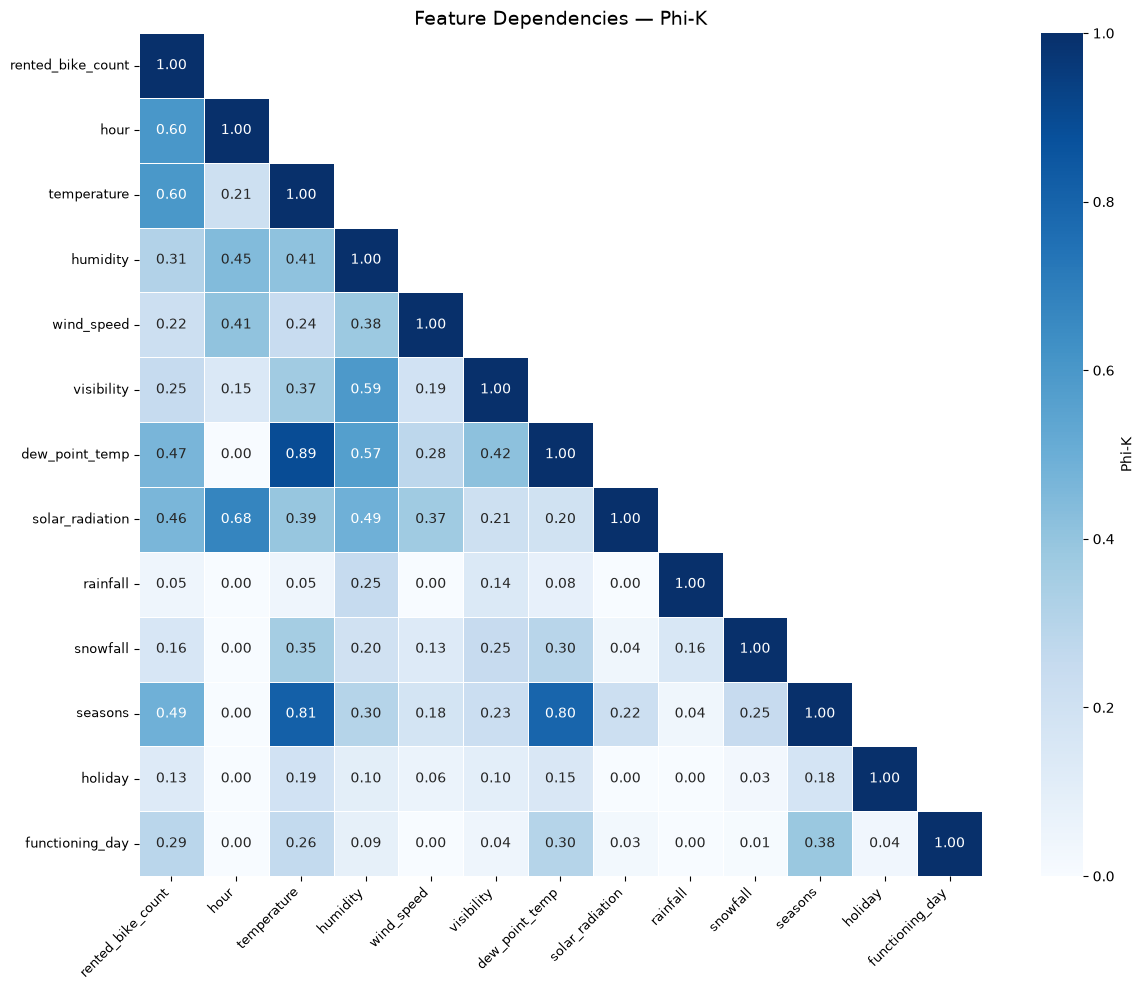

In [77]:
weather_cols = ["temperature", "humidity", "wind_speed", "visibility",
                "dew_point_temp", "solar_radiation", "rainfall", "snowfall"]
categorical_cols = ["seasons", "holiday", "functioning_day"]
target_col = "rented_bike_count"

analysis_cols = [target_col, "hour", *weather_cols, *categorical_cols]

phik_corr = (
    df[analysis_cols]
    .phik_matrix(
        interval_cols=[target_col, *weather_cols],
        bins=10, quantile=False, noise_correction=True,
        verbose=False, njobs=1,
    )
    .loc[analysis_cols, analysis_cols]
)

plt.figure(figsize=(13, 10))
ax = sns.heatmap(
    phik_corr,
    mask=np.triu(np.ones_like(phik_corr, dtype=bool), k=1),
    annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
    square=True, linewidths=0.4,
    cbar_kws={"label": "Phi-K"},
)
ax.set_title("Feature Dependencies — Phi-K", fontsize=14)
ax.tick_params(labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

### Numerical Feature Relationships — Pairplot

Визуальная проверка формы попарных связей числовых признаков:
линейности, нелинейности, скоплений и ограничений диапазона.

,feature_1,feature_2,phi_k
0,temperature,dew_point_temp,0.893
1,temperature,seasons,0.813
2,dew_point_temp,seasons,0.796
3,hour,solar_radiation,0.676
4,humidity,visibility,0.590
5,humidity,dew_point_temp,0.570
6,humidity,solar_radiation,0.489
7,hour,humidity,0.445
8,visibility,dew_point_temp,0.418
9,temperature,humidity,0.413


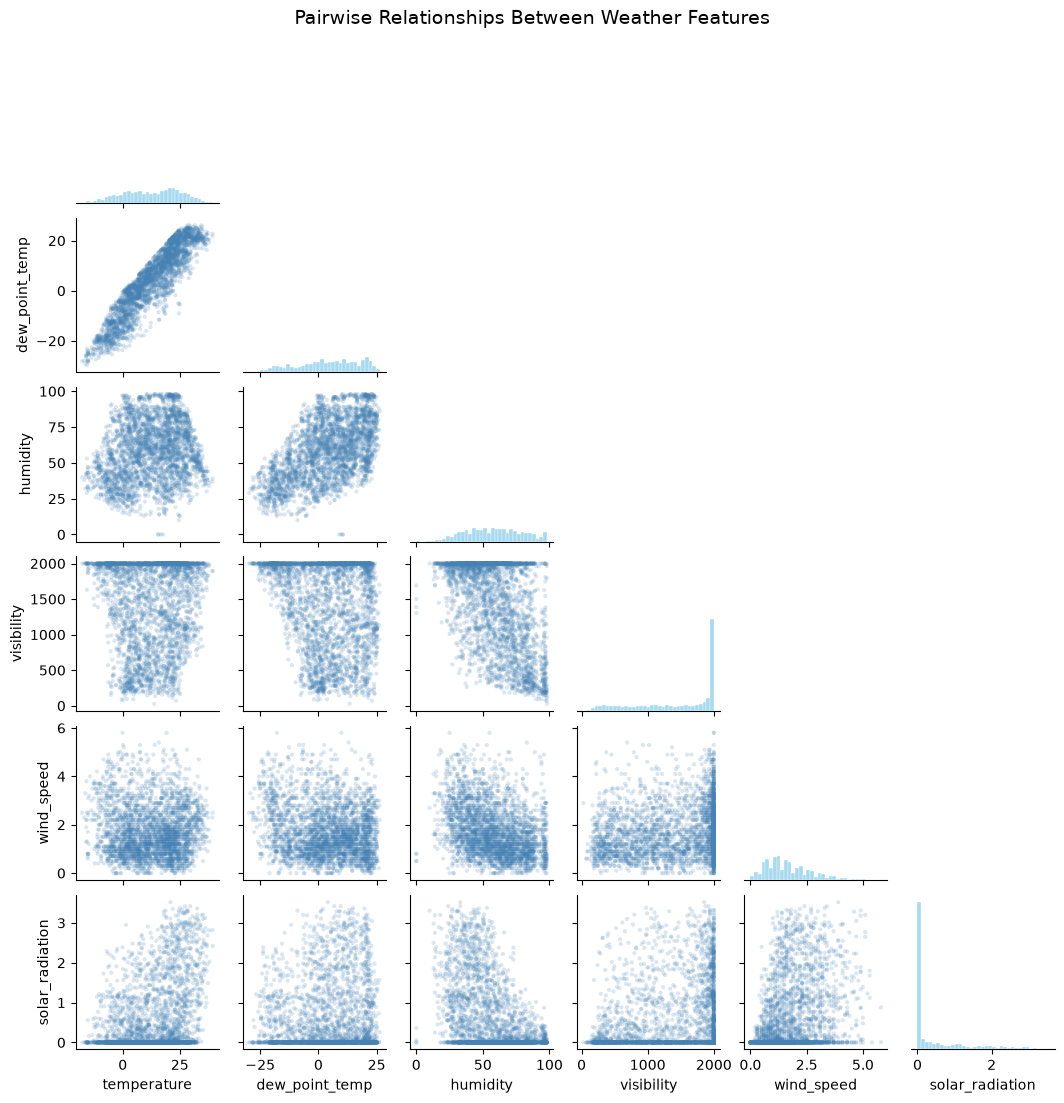

In [78]:
feature_phik = phik_corr.drop(index=target_col, columns=target_col)

top_feature_pairs = (
    feature_phik
    .where(np.triu(np.ones(feature_phik.shape, dtype=bool), k=1))
    .rename_axis(index="feature_1", columns="feature_2")
    .stack()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="phi_k")
)
display(top_feature_pairs.round(3))

pair_cols = ["temperature", "dew_point_temp", "humidity",
             "visibility", "wind_speed", "solar_radiation"]

g = sns.pairplot(
    df[pair_cols].sample(n=min(3000, len(df)), random_state=42),
    corner=True, diag_kind="hist", height=1.8,
    plot_kws={"s": 9, "alpha": 0.2, "color": "steelblue", "edgecolor": "none"},
    diag_kws={"bins": 35, "color": "skyblue", "edgecolor": "white"},
)
g.figure.suptitle("Pairwise Relationships Between Weather Features",
                  fontsize=14, y=1.02)
plt.show()

### Conclusion: Feature Correlations

Температура и точка росы тесно связаны (Пирсон = 0,913; Phi-K = 0,893).
В baseline оставляем оба признака; варианты без одного из них сравним
на тех же временных фолдах.

Для `hour` и `solar_radiation` линейная корреляция слабая (Пирсон = 0,145),
но Phi-K заметно выше (0,676). Форму связи лучше смотреть на почасовом
графике: сами коэффициенты её не показывают.

Среди рассмотренных признаков наибольший Phi-K с числом аренд имеют
`hour` и `temperature` (около 0,60).

## Temporal and Demand Dynamics

[Table of Contents](#Table-of-Contents)


Главный вопрос: как число аренд меняется во времени?

### Time-Series EDA Index

- [Проверка временного покрытия, пропущенных часов и дубликатов](#Temporal-Integrity-Check)
- [Суточный спрос и скользящее среднее за 7 дней](#Daily-Demand-Over-Time)
- [Почасовые профили спроса по типам дней](#Hourly-Demand-by-Day-Type)
- [Автокорреляция спроса и лаги 1, 24 и 168 часов](#Demand-Autocorrelation)
- [Итоги временного EDA: наблюдения, ограничения и кандидаты в признаки](#Time-Series-EDA-Summary)

### Temporal Integrity Check
[Index](#Time-Series-EDA-Index)

Проверка покрытия периода с 1 декабря 2017 года по 30 ноября 2018 года:
корректность часов, пропущенные временные отметки, дубликаты
и полнота каждого календарного дня.

In [79]:
time_check = df[["date", "hour"]].copy()
hours = pd.to_numeric(time_check["hour"], errors="coerce")

invalid_dates = time_check["date"].isna() | time_check["date"].ne(time_check["date"].dt.normalize())
invalid_hours = hours.isna() | ~hours.between(0, 23) | hours.mod(1).ne(0)

if (bad := invalid_dates | invalid_hours).any():
    print(f"Некорректных дат: {invalid_dates.sum():,}")
    print(f"Некорректных часов: {invalid_hours.sum():,}")
    display(time_check.loc[bad])
    raise ValueError(
        "Сначала исправь даты и часы: date должен содержать дату "
        "без времени, hour — целое число от 0 до 23."
    )

time_check["datetime"] = time_check["date"] + pd.to_timedelta(hours, unit="h")
was_sorted = time_check["datetime"].is_monotonic_increasing
time_check = time_check.sort_values("datetime")

expected_hours = pd.date_range("2017-12-01", "2018-11-30 23:00", freq="h")
actual_hours = pd.DatetimeIndex(time_check["datetime"].unique())
missing_hours = expected_hours.difference(actual_hours)
extra_hours = actual_hours.difference(expected_hours)
n_dup = time_check["datetime"].duplicated().sum()

incomplete_days = (
    time_check.groupby(time_check["datetime"].dt.normalize())["datetime"]
    .nunique()
    .reindex(expected_hours.normalize().unique(), fill_value=0)
    .pipe(lambda s: s[s.ne(24)].rename("unique_hours"))
)

is_complete = not (len(missing_hours) or len(extra_hours) or n_dup or len(incomplete_days))

print("=" * 70 + "\nTEMPORAL INTEGRITY CHECK\n" + "=" * 70)
print(
    f"Начало данных:                    {time_check['datetime'].min()}\n"
    f"Конец данных:                     {time_check['datetime'].max()}\n"
    f"Ожидаемое количество часов:       {len(expected_hours):,}\n"
    f"Фактическое количество строк:     {len(time_check):,}\n"
    f"Уникальных временных отметок:     {len(actual_hours):,}\n"
    f"Пропущенных часов:                {len(missing_hours):,}\n"
    f"Часов вне ожидаемого периода:     {len(extra_hours):,}\n"
    f"Дублирующих строк по времени:     {n_dup:,}\n"
    f"Дней с количеством часов != 24:   {len(incomplete_days):,}\n"
    f"Исходный порядок хронологический: {was_sorted}"
)
print(
    "\nИтог:",
    "Период покрыт полностью, каждый час представлен ровно один раз."
    if is_complete
    else "Обнаружены проблемы временного покрытия — смотри детали ниже.",
)

for label, frame in [
    ("Пропущенные часы",                 missing_hours.to_frame(index=False, name="datetime")),
    ("Часы вне ожидаемого периода",      extra_hours.to_frame(index=False, name="datetime")),
    ("Строки с повторяющимся временем",  time_check.loc[time_check["datetime"].duplicated(keep=False)]),
    ("Неполные дни",                     incomplete_days.to_frame()),
]:
    if len(frame):
        print(f"\n{label} — первые 20:")
        display(frame.head(20))

TEMPORAL INTEGRITY CHECK
Начало данных:                    2017-12-01 00:00:00
Конец данных:                     2018-11-30 23:00:00
Ожидаемое количество часов:       8,760
Фактическое количество строк:     8,760
Уникальных временных отметок:     8,760
Пропущенных часов:                0
Часов вне ожидаемого периода:     0
Дублирующих строк по времени:     0
Дней с количеством часов != 24:   0
Исходный порядок хронологический: True

Итог: Период покрыт полностью, каждый час представлен ровно один раз.


### Daily Demand Over Time
[Index](#Time-Series-EDA-Index)

Ежедневное суммарное количество аренд за период с 1 декабря 2017 года
по 30 ноября 2018 года. Скользящее среднее за 7 дней используется
для визуального сглаживания краткосрочных колебаний.

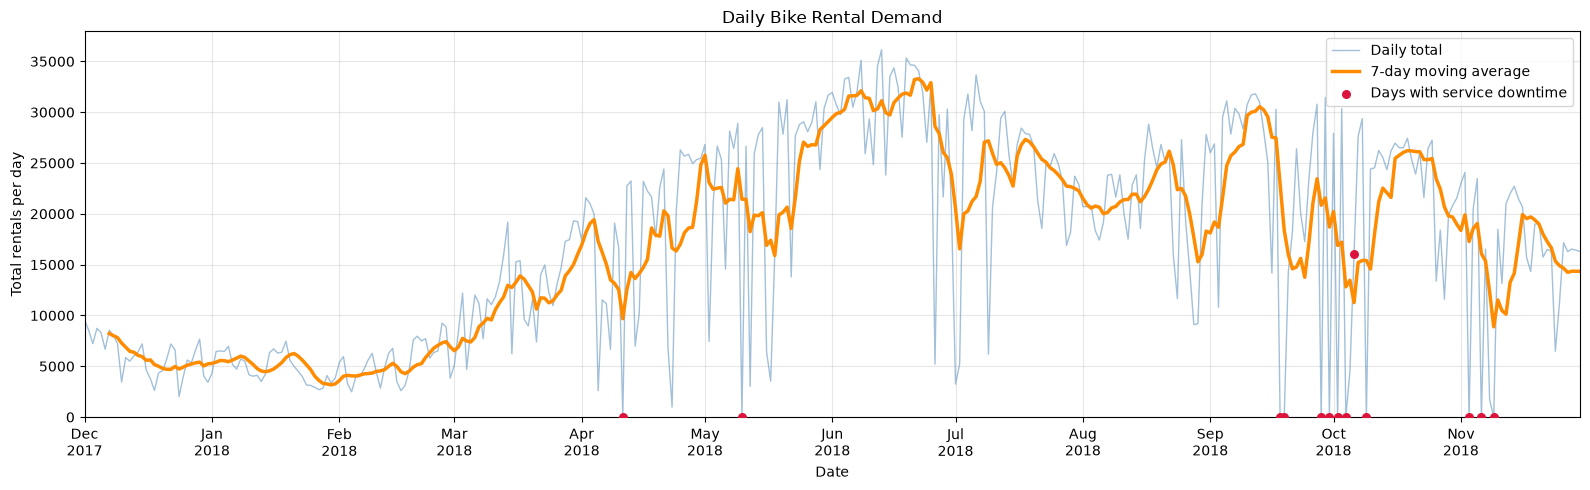

DAILY DEMAND SUMMARY
Количество дней:            365
Всего аренд за период:      6,172,314
Среднее за день:            16,910.4
Медиана за день:            17,730.0
Минимальный спрос:          0 (2018-04-11)
Максимальный спрос:         36,149 (2018-06-13)
Дней с нулевым спросом:     12
Дней с остановками:         13
Из них полностью без работы: 12


In [80]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

daily = (
    df.groupby("date")["rented_bike_count"]
      .sum(min_count=1)
      .sort_index()
      .to_frame("daily_rentals")
)
s = daily["daily_rentals"]
daily["rolling_mean_7d"] = s.rolling(7, min_periods=7).mean()

has_service = "functioning_day" in df.columns
if has_service:
    daily["non_operating_hours"] = (
        df["functioning_day"].eq("No").groupby(df["date"]).sum()
          .reindex(daily.index, fill_value=0)
    )

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(daily.index, s, color="steelblue", linewidth=1, alpha=0.5,
        label="Daily total")
ax.plot(daily.index, daily["rolling_mean_7d"], color="darkorange",
        linewidth=2.5, label="7-day moving average")

if has_service:
    downtime_days = daily[daily["non_operating_hours"] > 0]
    if not downtime_days.empty:
        ax.scatter(downtime_days.index, downtime_days["daily_rentals"],
                   color="crimson", s=30, zorder=3,
                   label="Days with service downtime")

ax.set(title="Daily Bike Rental Demand", xlabel="Date",
       ylabel="Total rentals per day",
       xlim=(daily.index.min(), daily.index.max()), ylim=(0, None))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print("=" * 60 + "\nDAILY DEMAND SUMMARY\n" + "=" * 60)
print(
    f"Количество дней:            {len(s):,}\n"
    f"Всего аренд за период:      {s.sum():,.0f}\n"
    f"Среднее за день:            {s.mean():,.1f}\n"
    f"Медиана за день:            {s.median():,.1f}\n"
    f"Минимальный спрос:          {s.min():,.0f} ({s.idxmin():%Y-%m-%d})\n"
    f"Максимальный спрос:         {s.max():,.0f} ({s.idxmax():%Y-%m-%d})\n"
    f"Дней с нулевым спросом:     {s.eq(0).sum():,}"
)

if has_service:
    dt = daily["non_operating_hours"]
    print(
        f"Дней с остановками:         {dt.gt(0).sum():,}\n"
        f"Из них полностью без работы: {dt.eq(24).sum():,}"
    )

#### Observations

- За исследуемые 365 дней зарегистрировано 6 172 314 аренд.
  Среднее дневное количество аренд — 16 910, медиана — 17 730.
- В зимние месяцы спрос ниже; с марта наблюдается рост,
  а наиболее высокий устойчивый уровень приходится на июнь.
- Максимальная дневная сумма — 36 149 аренд — зафиксирована
  13 июня 2018 года.
- Выявлено 12 дней полной остановки сервиса и один день
  с частичной остановкой. Нулевые дневные суммы в эти дни
  нельзя интерпретировать как отсутствие пользовательского спроса.

### Hourly Demand by Day Type
[Index](#Time-Series-EDA-Index)


Сравнение среднего почасового количества аренд в будни,
выходные и праздники. Праздники выделены в отдельную категорию
независимо от дня недели. Учитываются только часы работы сервиса.

DAY TYPE SUMMARY — operating hours only


,calendar_days,days_with_service,operating_hours,mean_hourly_rentals
day_type,,,,
Weekday,247,238,5712,756.2
Weekend,100,98,2345,698.1
Holiday,18,17,408,529.2


,peak_hour,peak_mean_rentals,lowest_hour,lowest_mean_rentals
day_type,,,,
Weekday,18,1766.3,4,121.0
Weekend,17,1186.1,5,128.7
Holiday,17,879.4,5,94.2


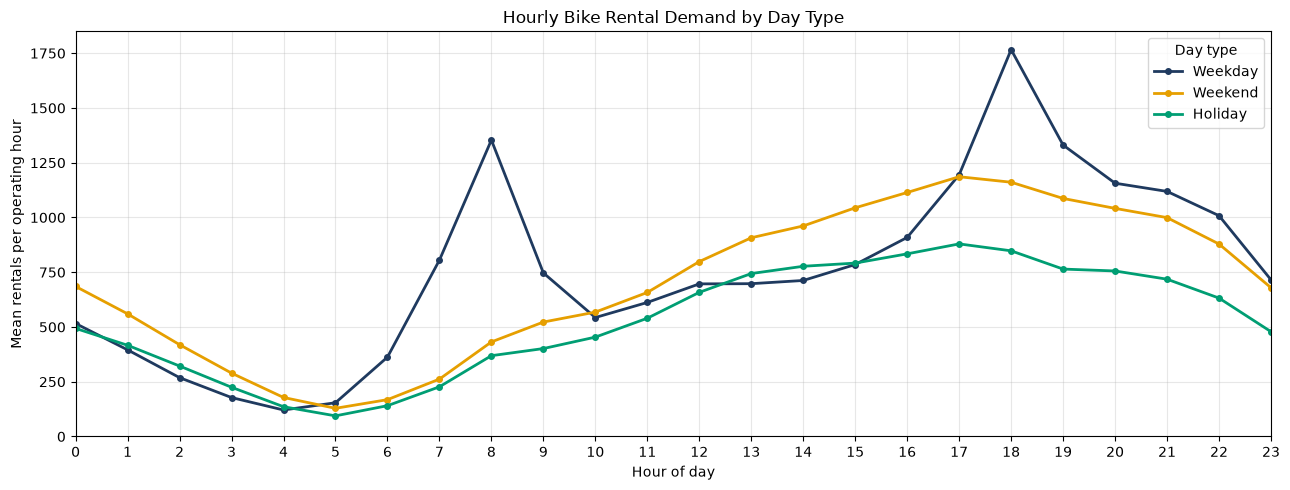

In [81]:
import matplotlib.pyplot as plt
import numpy as np

eda = df.copy()
eda["is_weekend"] = eda["date"].dt.day_of_week.isin([5, 6])

for col, allowed in {
    "holiday": ["Holiday", "No Holiday"],
    "functioning_day": ["Yes", "No"],
}.items():
    if not eda[col].isin(allowed).all():
        raise ValueError(f"Проверь значения в колонке {col}")

eda["day_type"] = np.select(
    [eda["holiday"].eq("Holiday"), eda["is_weekend"]],
    ["Holiday", "Weekend"],
    default="Weekday",
)

day_order = ["Weekday", "Weekend", "Holiday"]
operating = eda[eda["functioning_day"].eq("Yes")]

group_summary = (
    operating.groupby("day_type")
    .agg(
        days_with_service=("date", "nunique"),
        operating_hours=("hour", "size"),
        mean_hourly_rentals=("rented_bike_count", "mean"),
    )
    .reindex(day_order)
)
group_summary.insert(0, "calendar_days",
    eda.groupby("day_type")["date"].nunique().reindex(day_order))

print("DAY TYPE SUMMARY — operating hours only")
display(group_summary.round(1))

hourly_profiles = operating.pivot_table(
    index="hour", columns="day_type",
    values="rented_bike_count", aggfunc="mean",
).reindex(index=range(24), columns=day_order)

colors = {"Weekday": "#1F3A5F", "Weekend": "#E69F00", "Holiday": "#009E73"}

fig, ax = plt.subplots(figsize=(13, 5))
hourly_profiles.plot(
    ax=ax, marker="o", markersize=4, linewidth=2,
    color=[colors[c] for c in hourly_profiles.columns],
)
ax.set(title="Hourly Bike Rental Demand by Day Type",
       xlabel="Hour of day",
       ylabel="Mean rentals per operating hour",
       xticks=range(24), xlim=(0, 23), ylim=(0, None))
ax.grid(True, alpha=0.3)
ax.legend(title="Day type")
fig.tight_layout()


peak_summary = pd.DataFrame({
    "peak_hour": hourly_profiles.idxmax(),
    "peak_mean_rentals": hourly_profiles.max(),
    "lowest_hour": hourly_profiles.idxmin(),
    "lowest_mean_rentals": hourly_profiles.min(),
}).reindex(day_order)

display(peak_summary.round(1))

plt.show()

| Колонка             | Что означает                                                                                                                                                          | Пример: будни (Weekday)    |
| ------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------- | -------------------------- |
| calendar_days       | Число календарных дат этого типа, включая дни, когда сервис был полностью закрыт. Это единственная колонка таблицы, рассчитанная до фильтра functioning_day == "Yes". | 247 дней                   |
| days_with_service   | Число дат, когда сервис работал хотя бы один час.                                                                                                                     | 238 дней                   |
| operating_hours     | Число почасовых строк со статусом functioning_day == "Yes".                                                                                                           | 5 712 часов                |
| mean_hourly_rentals | Среднее число аренд по всем часам работы в этой группе, без разделения по часу суток.                                                                                 | 756,2 аренды за час работы |

| Колонка             | Что означает                                             | Пример: будни (Weekday)                 |
| ------------------- | -------------------------------------------------------- | --------------------------------------- |
| peak_hour           | Час суток с наибольшим средним числом аренд.             | 18:00                                   |
| peak_mean_rentals   | Среднее число аренд в этот час по всем подходящим датам. | 1 766,3 аренды в среднем в будние 18:00 |
| lowest_hour         | Час суток с наименьшим средним числом аренд.             | 04:00                                   |
| lowest_mean_rentals | Среднее число аренд в этот час по всем подходящим датам. | 121,0 аренды в среднем в будние 04:00   |

#### Observations

- В будни наблюдаются два выраженных пика среднего почасового спроса:
  утренний около 08:00 и вечерний в 18:00.
  Максимальное среднее значение — 1766 аренд в 18:00.
- В выходные выраженный утренний пик отсутствует. Спрос постепенно
  растёт в течение дня и достигает максимума в 17:00 — 1186 аренд.
- Праздничный профиль по форме ближе к выходному, но средний уровень
  аренд ниже. Максимум — 879 аренд в 17:00.
- Объединение будней и выходных в категорию No Holiday скрывало
  различия их суточных профилей.
- Анализ выполнен только по часам работы сервиса. Праздники
  представлены 17 днями с работающим сервисом, поэтому выводы
  по этой группе требуют большей осторожности.
- Профили усреднены за весь год: различия погоды и сезонного состава
  групп в этом сравнении отдельно не учитываются.

#### Feature Engineering Ideas

- Создать признаки циклического расстояния до пиковых часов:
  - hour_dist_to_8 — расстояние до 08:00;
  - hour_dist_to_18 — расстояние до 18:00.
- Расстояние считать по 24-часовому кругу:
  d(h, p) = min(|h − p|, 24 − |h − p|).
- Дополнительно проверить расстояние до ближайшего пика:
  hour_dist_to_peak = min(hour_dist_to_8, hour_dist_to_18).
- Проверить взаимодействие с типом дня: утренний пик выражен
  прежде всего в будни.
- Полезность признаков проверить на временной валидации
  относительно модели с исходным hour.
- При подборе пиков по данным использовать только обучающую
  часть, не весь датасет.


```python
for peak in [8, 18]:
    distance = (df["hour"] - peak).abs()
    df[f"hour_dist_to_{peak}"] = np.minimum(distance, 24 - distance)

df["hour_dist_to_peak"] = df[
    ["hour_dist_to_8", "hour_dist_to_18"]
].min(axis=1)
```

### Hourly Demand by Season

Среднее количество аренд по часам суток в разные сезоны.
Учитываются только часы работы сервиса.

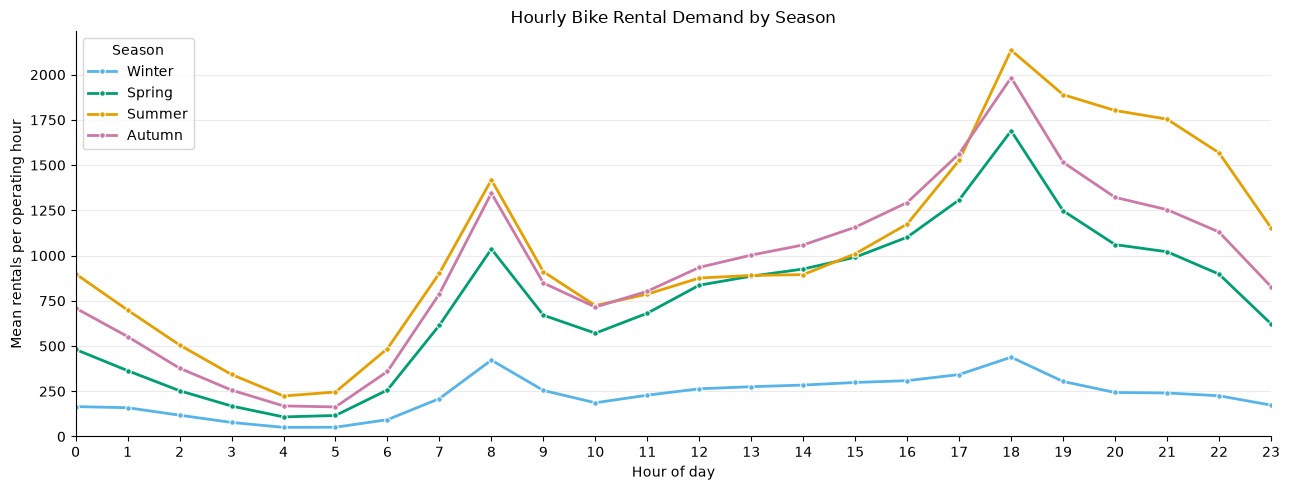

In [82]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]
season_palette = {
    "Winter": "#56B4E9", "Spring": "#009E73",
    "Summer": "#E69F00", "Autumn": "#CC79A7",
}

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(
    data=df[df["functioning_day"].eq("Yes")],
    x="hour", y="rented_bike_count", hue="seasons",
    hue_order=season_order, palette=season_palette,
    estimator="mean", errorbar=None,
    marker="o", linewidth=2, markersize=4,
    ax=ax,
)
ax.set(title="Hourly Bike Rental Demand by Season",
       xlabel="Hour of day", ylabel="Mean rentals per operating hour",
       xticks=range(24), xlim=(0, 23), ylim=(0, None))
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Season")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

На сезонных профилях видны утренний подъём около 08:00 и вечерний
максимум около 18:00. Эти профили объединяют все типы дней в часы
работы сервиса. При разбиении по типу дня резкий утренний пик виден
на общем профиле будней, но не на профилях выходных и праздников.

### Conclusion: Temporal and Demand Dynamics

Почасовая сетка полная: пропущенных и повторяющихся часов нет.
Дневные итоги отражают фактические аренды, в том числе нули при закрытии
сервиса, а не потенциальный спрос.

В часы работы сервиса у будней заметен утренний пик около 08:00,
а максимум среднего числа аренд приходится на 18:00. У выходных
и праздников такого выраженного утреннего пика нет, а максимум
приходится на 17:00. Это сравнение по одному году наблюдений,
без выравнивания групп по погоде и сезону.

## Preprocessing Plan
[Table of Contents](#Table-of-Contents)

# таблица для baseline

| Фича                        | Baseline: регрессия                                                           | Baseline: CatBoost                                    |
| --------------------------- | ----------------------------------------------------------------------------- | ----------------------------------------------------- |
| date                        | Для хронологической сортировки и разбиения; не подаём в модель                | То же                                                 |
| hour                        | Числовой признак, масштабируем                                                | Числовой признак без масштабирования                  |
| seasons                     | OHE, без задания порядка сезонов                                              | Исходная категория, без ручного OHE                   |
| holiday                     | OHE                                                                           | Исходная категория, без ручного OHE                   |
| functioning_day             | Один столбец: Yes → 1, No → 0                                                 | Исходная категория                                    |
| temperature, dew_point_temp | Сохраняем оба признака. `log1p` и подготовительные сдвиги из EDA не применяем, и масштабируем конечно же | Оставляем оба в исходном виде                         |
| humidity                    | Масштабируем; 17 нулей не заменяем                                            | Оставляем в исходном виде, включая нули               |
| wind_speed                  | Масштабируем без клипирования                                                 | Оставляем без клипирования                            |
| visibility                  | Стандартизируем весь столбец без предварительных замен и без отдельного флага | Оставляем в исходном виде, без флага                  |
| solar_radiation             | Масштабируем без клипирования и флага                                         | Оставляем в исходном виде, без клипирования и флага   |
| rainfall, snowfall          | Масштабируем исходные величины; нули сохраняем, флаги не добавляем            | Оставляем исходные величины, включая нули; без флагов |


Для Linear Regression / Ridge числовые входные признаки (hour и погодные признаки) стандартизируем через StandardScaler. Среднее и стандартное отклонение считаем только на обучающей части каждого временного фолда и без пересчёта применяем к валидации. OHE-столбцы, бинарный functioning_day и таргет не масштабируем. Для CatBoost числовые признаки не масштабируем.

# идеи для генерации фич
| Фича                         | Идея для регрессии                                                                                       | Идея для CatBoost                                                                                    |
| ---------------------------- | -------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------- |
| date → day_of_week, day_type | Проверить day_of_week через OHE. Отдельно сравнить day_type через OHE вместо holiday                     | Проверить те же варианты как категориальные признаки, без ручного OHE                                |     
| hour                         | Сравнить числовой час с циклической парой sin/cos. Отдельно проверить взаимодействие часа с day_type     | Сначала проверить day_type вместе с исходным hour; циклическую пару сравнить отдельным экспериментом |     
| temperature, dew_point_temp  | Сравнить оба признака с вариантами, где оставлен только один                                             | То же; не удалять признак заранее из-за корреляции                                                   |     
| humidity                     | Сначала проверить нули. Заменить их на расчетную величину                                                | То же                                                                                                |     
| wind_speed                   | Сравнить `log1p` → `StandardScaler` с baseline. Клипирование по 99-му перцентилю — отдельный эксперимент | Проверить то же клипирование без масштабирования                                                     |     
| visibility                   | Добавить visibility == 2000 рядом с числовым признаком                                                   | Проверить тот же флаг рядом с исходной величиной                                                     |     
| solar_radiation              | Раздельно проверить флаг solar_radiation > 0 и верхнее клипирование по 99-му перцентилю                  | Те же два эксперимента по отдельности, без масштабирования                                           |     
| rainfall, snowfall           | Проверить rainfall > 0 и snowfall > 0 в дополнение к исходным величинам                                  | Проверить те же флаги, не заменяя ими исходные величины                                              |     


пс про wind_speed Сначала заменяем скорость ветра на `log1p(wind_speed)`, то есть $ln⁡(1+wind\_speed)$ и уже этот столбец стандартизируем.


## EDA Conclusion
[Table of Contents](#Table-of-Contents)

Датасет содержит 8 760 почасовых наблюдений за один год. Пропущенных
или повторяющихся часов нет; `isna()` не выявил пропусков. При этом
17 нулевых значений влажности требуют проверки, а скопление значений
видимости на отметке 2000 не подтверждает, что это предел датчика.
В baseline эти значения сохраняем без замены и клипирования.

Во всех 295 часах со статусом `functioning_day = No` число аренд
равно нулю. Эти нули отражают закрытие сервиса, а не отсутствие
потенциального спроса. В часы работы у будней заметен утренний пик
около 08:00, а максимум среднего числа аренд приходится на 18:00.
У выходных и праздников выраженного утреннего пика нет, а максимум
приходится на 17:00. Это наблюдение за один год, без выравнивания
групп по погоде и сезону.

В baseline сохраняем все строки и оба температурных признака.
Предсказываем число аренд для того же часа, не сдвигая таргет
и не меняя его шкалу. EDA проводился на всём наборе; дальнейшие
эксперименты сравниваем на одинаковых временных фолдах, а последний
период не используем для отбора признаков и настройки моделей.